# Notebook 4: Korrelation und Zusammenhang

**Statistik für Data Science** · Kurs 3,906 · Bachelor Computer Science · HS2026
Universität St. Gallen · Begleitmaterial zur Übung

---

Dieses Notebook führt die Inhalte von **VL04 (Korrelation und Zusammenhang)** in Python aus. Jeder Unterabschnitt beginnt mit einem Problem, holt die passende Theorie aus der Vorlesung, löst das Problem im Code und sagt, was das Ergebnis bedeutet. Am Ende steht jeweils eine Frage für euren eigenen Datensatz.

**Die vier Schritte.** Sie kehren in jedem Unterabschnitt in derselben Reihenfolge wieder:

| Schritt | Was dort steht |
|---|---|
| **Problem.** | Eine konkrete Frage, meist mit einer Zahl aus den Daten |
| **Theorie.** | Was die Vorlesung dazu sagt, mit der Folie: *Vorlesung: Folie «…»* |
| **Code.** | `# Rechnen` berechnet die Statistik, `# Darstellen` zeigt vorher und nachher |
| **Bedeutung.** | Was der Output zeigt und welche Entscheidung daraus folgt |
| **Euer Datensatz.** | Dieselbe Frage für eure eigene Variable |

**Übersicht.** Die Fragen **Euer Datensatz** am Ende jedes Unterabschnitts und Abschnitt 6 («Transfer in der Übung») führen die Übertragung auf eure eigenen Daten.

| | Unterabschnitt | Problem |
|---|---|---|
| **1** | **Streudiagramme lesen** | **Bewegt sich y mit x?** |
| 1.1 | Zwei Variablen, ein Punkt pro Beobachtung | 891 Passagiere, 714 vollständige Paare: Haben Ältere mehr bezahlt? |
| 1.2 | Form und Stärke lesen | Drei Wolken: Welche ist am stärksten, und welche Form hat jede? |
| **2** | **Kovarianz und Pearson r** | **Wie wird aus der Wolke eine Zahl?** |
| 2.1 | Kovarianz zählt gemeinsame Abweichungen | 3.33 von Hand: Was liefert pandas, und was für 714 Passagiere? |
| 2.2 | Die Einheit kürzt sich weg: Pearson r | Pfund oder Pence: Die Kovarianz springt um den Faktor 100, was bleibt? |
| 2.3 | Ein Punkt kann r kippen | Ein elfter Punkt drückt r von 0.99 nach unten: löschen? |
| **3** | **Spearman und Kendall** | **Was tun bei Krümmung, Ausreissern und Ties?** |
| 3.1 | Spearman ist Pearson auf den Rängen | Drei Tickets zu 512 Pfund: Was ändert sich, wenn nur die Reihenfolge zählt? |
| 3.2 | Kendall zählt geordnete Paare | Die Klasse hat drei Werte für 891 Passagiere: Welches Mass passt? |
| 3.3 | Die Form wählt das Mass | Gerade, Kurve, U: Welches Mass sieht welchen Zusammenhang? |
| **4** | **Zusammenhang und Ursache** | **Was dürfen wir schliessen?** |
| 4.1 | Eine Drittvariable erzeugt den Zusammenhang | Eis und Badeunfälle korrelieren, obwohl Eis nichts bewirkt: Woher kommt r? |
| 4.2 | Gemeinsame Trends täuschen | Zwei wachsende Reihen, r = 0.97: Was bleibt ohne den Trend? |
| 4.3 | Simpson: das Aggregat dreht den Trend | Über alle Pinguine fällt die Schnabeltiefe mit der Länge: auch je Art? |
| **5** | **Viele Variablen auf einmal** | **Welche Paare verdienen den Plot?** |
| 5.1 | Korrelationsmatrix und Heatmap | Sechs Spalten, 15 Paare: Welche lohnen den Plot, und was zählt pclass darin? |
| 5.2 | Pairplot lesen | Vier Pinguin-Masse, eine Grafik: Wo steckt Simpson? |

**Datensätze.** Der Titanic-Datensatz führt die Analyse aus NB01 bis NB03 fort: Alter und Ticketpreis bilden das Paar, an dem Kovarianz, r und ρ nachgerechnet werden; die Vorlesung nennt dafür «etwa 0.1». Die Pinguindaten liefern eine gerade Wolke (Flossenlänge und Gewicht) und den Fall, in dem das Aggregat die Richtung umkehrt (Schnabellänge und Schnabeltiefe). Simulierte Daten mit bekannter Wahrheit stehen dort, wo ein Mechanismus sichtbar werden soll: der Hebelpunkt, die Drittvariable, der gemeinsame Trend.

**Ein Begriff vorweg: `method=`.** Die Korrelation rechnet in pandas `Series.corr(andere, method=...)` oder `DataFrame.corr(method=...)`. Ohne Angabe gilt `method='pearson'`. `method='spearman'` ersetzt die Werte durch Ränge (gleiche Werte bekommen den mittleren Rang) und rechnet darauf Pearson; `method='kendall'` zählt konkordante und diskordante Paare (Kendalls tau-b, das Ties berücksichtigt). Für die beiden Rangmasse braucht pandas das Paket `scipy`; es ist seit diesem Notebook in der Umgebung.

## 0. Setup

Es gelten dieselben Konventionen wie in NB01 bis NB03: wenige Standardpakete und ein zentraler Seed. Beide Datensätze werden hier einmal geladen. Die Rangmasse rechnet pandas selbst; `scipy` wird nur im Hintergrund gebraucht und deshalb nicht importiert.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

SEED = 42
RNG = np.random.default_rng(SEED)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (7.5, 4.2)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

ARTEN = {'Adelie': '#2166AC', 'Chinstrap': '#B45309', 'Gentoo': '#15803D'}   # Farben der Decks

In [2]:
titanic = sns.load_dataset('titanic')
penguins = sns.load_dataset('penguins')

print(f'Titanic:  {titanic.shape[0]} Zeilen, {titanic.shape[1]} Spalten')
print(f'Pinguine: {penguins.shape[0]} Zeilen, {penguins.shape[1]} Spalten')

Titanic:  891 Zeilen, 15 Spalten
Pinguine: 344 Zeilen, 7 Spalten


---

## 1. Streudiagramme lesen

*Vorlesung: Abschnitt «Streudiagramme lesen». Leitfrage: Bewegt sich y mit x?*

NB02 und NB03 haben immer eine Variable angeschaut. Jetzt kommen zwei zusammen: Jeder Punkt ist eine Beobachtung mit zwei Werten. Bevor irgendeine Zahl gerechnet wird, lesen wir die Wolke: Richtung, Form, Stärke.

### 1.1 Zwei Variablen, ein Punkt pro Beobachtung

**Problem.** Der Titanic-Datensatz hat 891 Passagiere; das Alter fehlt bei 177, der Ticketpreis bei keinem. Für die Frage «Haben ältere Passagiere mehr bezahlt?» braucht jeder Punkt beide Werte derselben Person. Mit wie vielen Punkten rechnen wir, und was zeigt die Wolke?

**Theorie.** *Vorlesung: Folien «Zwei Variablen, ein Punkt pro Beobachtung», «Was heisst ‹Zusammenhang›?»*

$x$ ist die erklärende Variable (unabhängige Variable, Prädiktor) und kommt auf die waagrechte Achse, $y$ die Zielvariable (abhängige Variable, Response) auf die senkrechte. Entscheidend ist, dass beide Werte zur selben Beobachtung gehören: Erst dadurch wird aus zwei Spalten ein Wertepaar, das ein Punkt wird. Zusammenhang heisst: $y$ ändert sich systematisch mit $x$. Steigen die Punkte nach rechts, ist er positiv, fallen sie, negativ; ohne Muster gibt es keinen. Für die Korrelation spielt die Rollenverteilung keine Rolle, $r$ von $x$ mit $y$ ist dasselbe wie $r$ von $y$ mit $x$.

**Code.** Die Paare entstehen mit `dropna` auf beiden Spalten zugleich, n vorher und nachher. Vorher zeigt die Grafik die beiden Variablen getrennt, wie in NB02; nachher steht jeder Passagier als Punkt mit beiden Werten, die Randverteilungen laufen mit.

In [3]:
# Rechnen
paare = titanic[['age', 'fare']].dropna()        # nur Zeilen, die beide Werte haben
alter, preis = paare['age'], paare['fare']

print(f"Passagiere: {len(titanic)}, mit Alter: {titanic['age'].notna().sum()}, "
      f"mit Preis: {titanic['fare'].notna().sum()}, mit beidem: {len(paare)}")
print(f'Mittelwerte der Paare: Alter {alter.mean():.2f} Jahre, Preis {preis.mean():.2f} Pfund')

rechts_oben = ((alter > alter.mean()) & (preis > preis.mean())).sum()
links_unten = ((alter < alter.mean()) & (preis < preis.mean())).sum()
print(f'Älter und teurer als der Mittelwert: {rechts_oben} Passagiere, '
      f'jünger und billiger: {links_unten}, zusammen {(rechts_oben + links_unten) / len(paare):.1%}')

Passagiere: 891, mit Alter: 714, mit Preis: 891, mit beidem: 714
Mittelwerte der Paare: Alter 29.70 Jahre, Preis 34.69 Pfund
Älter und teurer als der Mittelwert: 98 Passagiere, jünger und billiger: 310, zusammen 57.1%


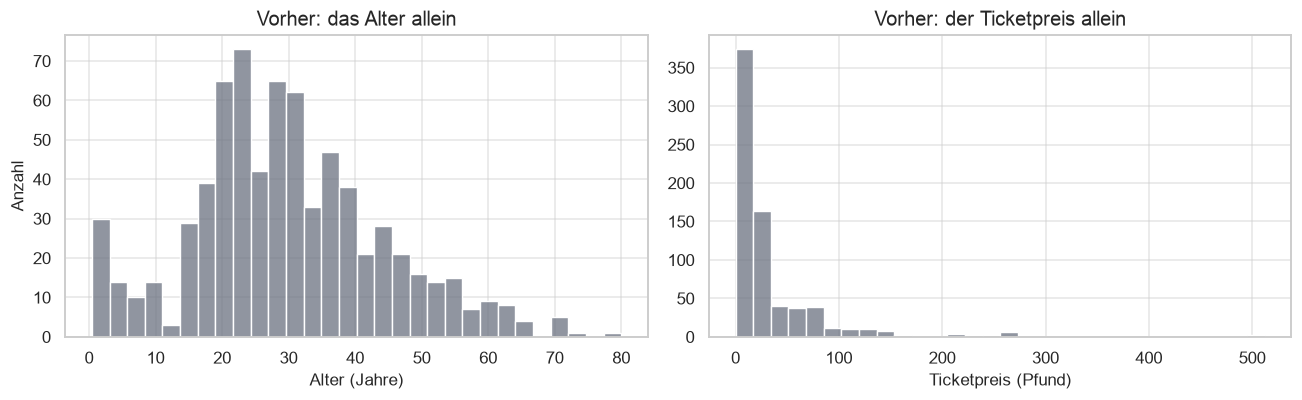

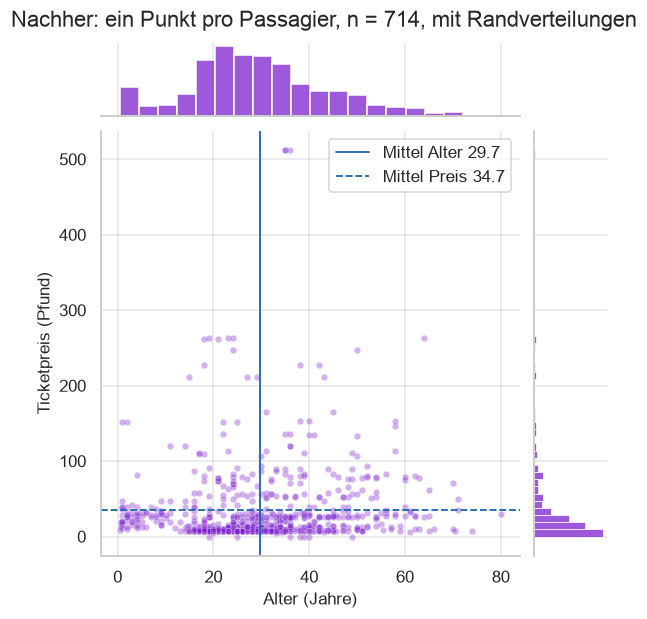

In [4]:
# Darstellen
fig, achsen = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(alter, bins=30, color='#6B7280', edgecolor='white', ax=achsen[0])
achsen[0].set(title='Vorher: das Alter allein', xlabel='Alter (Jahre)', ylabel='Anzahl')
sns.histplot(preis, bins=30, color='#6B7280', edgecolor='white', ax=achsen[1])
achsen[1].set(title='Vorher: der Ticketpreis allein', xlabel='Ticketpreis (Pfund)', ylabel='')
plt.tight_layout()
plt.show()

g = sns.jointplot(x=alter, y=preis, kind='scatter', color='#7E22CE', height=5.5,
                  joint_kws={'alpha': 0.35, 's': 18})
g.ax_joint.axvline(alter.mean(), color='#2166AC', linewidth=1.2, label=f'Mittel Alter {alter.mean():.1f}')
g.ax_joint.axhline(preis.mean(), color='#2166AC', linewidth=1.2, linestyle='--',
                   label=f'Mittel Preis {preis.mean():.1f}')
g.ax_joint.legend(loc='upper right')
g.set_axis_labels('Alter (Jahre)', 'Ticketpreis (Pfund)')
g.figure.suptitle(f'Nachher: ein Punkt pro Passagier, n = {len(paare)}, mit Randverteilungen', y=1.02)
plt.show()

**Bedeutung.** Von 891 Passagieren tragen 714 beide Werte; die 177 ohne Alter fallen aus jedem Paar heraus, und dieses n gehört in den Bericht, nicht die 891. Die Wolke steigt kaum: 408 der 714 Punkte (57.1 Prozent) liegen rechts oben oder links unten, also auf beiden Achsen über oder auf beiden unter dem Mittelwert, nur wenig mehr als die Hälfte. Die Randverteilungen zeigen, was NB02 schon wusste: Der Preis ist rechtsschief mit wenigen sehr teuren Tickets, das Alter ungefähr symmetrisch. Ob «kaum» auch «kein Zusammenhang» heisst, entscheidet erst eine Zahl, und die braucht genau diese 714 Paare (Kapitel 2).

> **Euer Datensatz.** Welche zwei metrischen Variablen beantworten eure Forschungsfrage, und welche davon ist x? Wie viele Zeilen haben beide Werte, und steht dieses n in eurem Log?

### 1.2 Form und Stärke lesen

**Problem.** Drei simulierte Wolken A, B und C mit je 60 Punkten: A steigt am steilsten, B liegt am engsten um eine Gerade, C biegt sich nach oben. Ohne zu rechnen: Welche hat den stärksten Zusammenhang, und welche Form hat jede?

**Theorie.** *Vorlesung: Folien «Linear oder monoton?», «Schätzt selbst: A, B oder C?», «Lösung: A, B und C»*

Linear heisst $y \approx a + b\,x$, überall dieselbe Steigung. Monoton heisst: Steigt $x$, steigt $y$ immer mit, die Steigung darf sich ändern; jede lineare Beziehung ist monoton, nicht umgekehrt. Weder noch ist etwa Stress und Leistung, die erst gemeinsam steigen und dann auseinanderlaufen. Die Stärke ist etwas anderes als die Steigung: Stark heisst eng um eine Linie. Eine steile Wolke ist noch lange keine starke. Und die Form entscheidet, welches Mass passt: Pearson misst Linearität, Spearman Monotonie.

**Code.** Drei Wolken mit bekannter Wahrheit: A hat Steigung 3 und viel Rauschen, B Steigung 1 und wenig Rauschen, C folgt einer Exponentialkurve. Für jede wird $r$ gerechnet. Vorher stehen die Wolken ohne Zahlen, nachher mit $r$ und einer eingepassten Geraden.

In [5]:
# Rechnen
n = 60
x_a = RNG.uniform(0, 10, n); y_a = 3 * x_a + RNG.normal(0, 12, n)          # steil, breit
x_b = RNG.uniform(0, 10, n); y_b = 1 * x_b + RNG.normal(0, 1, n)           # flach, eng
x_c = RNG.uniform(0, 10, n); y_c = np.exp(x_c / 2.2) + RNG.normal(0, 1, n)  # monoton, gekrümmt

wolken = {'A': (x_a, y_a), 'B': (x_b, y_b), 'C': (x_c, y_c)}
for name, (x, y) in wolken.items():
    steigung, _ = np.polyfit(x, y, 1)                       # Gerade nur zur Anschauung
    print(f'Wolke {name}: Steigung der Geraden {steigung:.2f}, r = {np.corrcoef(x, y)[0, 1]:.2f}')

Wolke A: Steigung der Geraden 2.94, r = 0.68
Wolke B: Steigung der Geraden 0.95, r = 0.94
Wolke C: Steigung der Geraden 6.28, r = 0.89


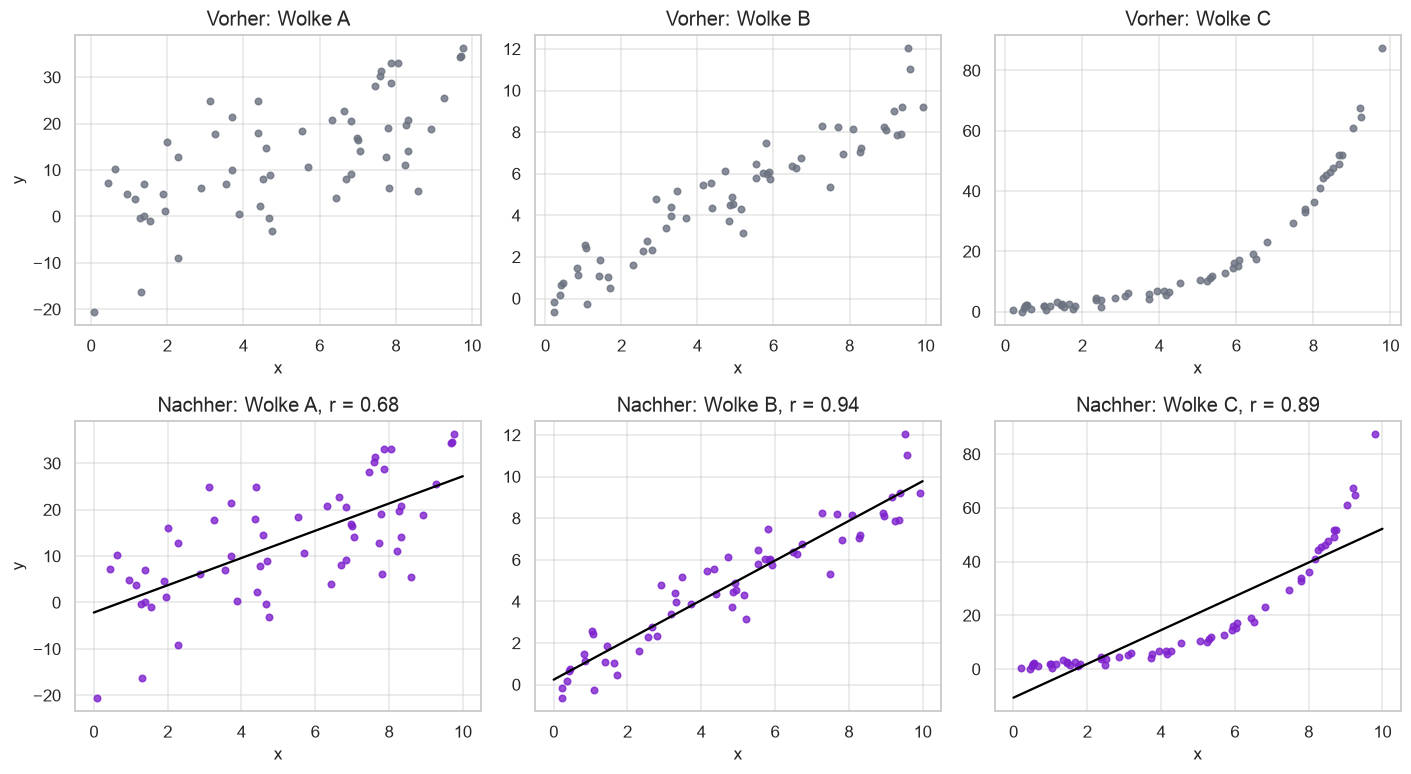

In [6]:
# Darstellen
fig, achsen = plt.subplots(2, 3, figsize=(13, 7.2))
for spalte, (name, (x, y)) in enumerate(wolken.items()):
    achsen[0, spalte].scatter(x, y, s=18, color='#6B7280', alpha=0.8)
    achsen[0, spalte].set(title=f'Vorher: Wolke {name}', xlabel='x', ylabel='y' if spalte == 0 else '')

    steigung, abschnitt = np.polyfit(x, y, 1)
    gitter = np.linspace(0, 10, 50)
    achsen[1, spalte].scatter(x, y, s=18, color='#7E22CE', alpha=0.8)
    achsen[1, spalte].plot(gitter, abschnitt + steigung * gitter, color='black', linewidth=1.5)
    achsen[1, spalte].set(title=f'Nachher: Wolke {name}, r = {np.corrcoef(x, y)[0, 1]:.2f}',
                          xlabel='x', ylabel='y' if spalte == 0 else '')
plt.tight_layout()
plt.show()

**Bedeutung.** B ist am stärksten (r = 0.94), obwohl A dreimal steiler steigt (r = 0.68): Die Stärke ist die Enge um die Gerade, die Steigung geht in r nicht ein. A und B sind linear. C ist monoton, aber nicht linear: Die Punkte liegen systematisch erst über, dann unter, dann wieder über der Geraden, und r = 0.89 unterschätzt eine Reihenfolge, die fast perfekt stimmt (dazu Kapitel 3). Deshalb zuerst die Form benennen, linear, monoton oder weder noch, und erst dann eine Zahl wählen.

> **Euer Datensatz.** Welche Form hat die Wolke eures wichtigsten Paars: linear, monoton oder weder noch? Und ist sie steil oder eng? Schreibt beides als Wörter ins Log, bevor ihr eine Zahl rechnet.

> **Take-Home Streudiagramme lesen**
>
> 1. **Erst plotten:** Jede Korrelation beginnt mit dem Streudiagramm; die Zahl verrät die Form nicht.
> 2. **Form benennen:** linear, monoton oder weder noch. Die Form wählt das Mass.
> 3. **Stärke ist Enge** um eine Linie. Die Steigung ist etwas anderes.
> 4. **n ist die Zahl der Paare** mit beiden Werten, nicht die Zahl der Zeilen.
>
> x auf die waagrechte Achse, y auf die senkrechte, und beide Werte gehören zur selben Beobachtung.

---

## 2. Kovarianz und Pearson r

*Vorlesung: Abschnitt «Kovarianz und Pearson r». Leitfrage: Wie wird aus der Punktwolke eine Zahl?*

Bis jetzt haben wir hingeschaut. Jetzt wird aus dem Bild eine Zahl: erst die Kovarianz mit ihrem Problem der Einheiten, dann Pearson $r$, und am Schluss, wo $r$ an seine Grenzen kommt.

### 2.1 Kovarianz zählt gemeinsame Abweichungen

**Problem.** Die Vorlesung rechnet für X = (1, 2, 3, 4) und Y = (2, 4, 6, 8) die Kovarianz 3.33 von Hand. Was liefert pandas für dieselben vier Paare, und was für die 714 Passagiere: Überwiegen bei Alter und Preis die Quadranten rechts oben und links unten?

**Theorie.** *Vorlesung: Folien «Kovarianz zählt gemeinsame Abweichungen», «Rechenbeispiel: Kovarianz»*

$$\text{Cov}(X,Y)=\frac{1}{n-1}\sum_i (x_i-\bar{x})(y_i-\bar{y})$$

Ein Kreuz durch die Mittelwerte teilt die Wolke in vier Quadranten. Liegt ein Punkt rechts oben oder links unten, sind beide Abweichungen gleich gerichtet und das Produkt ist positiv; links oben oder rechts unten ist es negativ. Die Kovarianz summiert die Produkte und teilt durch $n - 1$: Sie sagt, welche Quadranten überwiegen. Die Varianz aus VL02 ist die Kovarianz einer Variable mit sich selbst.

**Code.** Erst das Beispiel der Vorlesung: Produkte der Abweichungen, Summe durch $n - 1$, Gegenprobe mit `.cov()`. Dann dieselbe Rechnung für Alter und Preis mit der Zählung je Quadrant. Vorher die Wolke, nachher dieselbe Wolke mit dem Mittelwertkreuz, das die vier Quadranten trennt.

In [7]:
# Rechnen
x = pd.Series([1, 2, 3, 4]); y = pd.Series([2, 4, 6, 8])
tabelle = pd.DataFrame({'x': x, 'y': y, 'x - x̄': x - x.mean(), 'y - ȳ': y - y.mean()})
tabelle['Produkt'] = tabelle['x - x̄'] * tabelle['y - ȳ']
print(tabelle.to_string(index=False))
print(f"\nSumme der Produkte {tabelle['Produkt'].sum():.1f}, geteilt durch n - 1 = {len(x) - 1}: "
      f"{tabelle['Produkt'].sum() / (len(x) - 1):.4f}")
print(f'pandas x.cov(y):   {x.cov(y):.4f}   (teilt durch n - 1, wie .var() in NB02)')
print(f'NumPy np.cov:      {np.cov(x, y)[0, 1]:.4f}   (ebenfalls n - 1, ddof=1 ist Standard)')

 x  y  x - x̄  y - ȳ  Produkt
 1  2    -1.5   -3.0      4.5
 2  4    -0.5   -1.0      0.5
 3  6     0.5    1.0      0.5
 4  8     1.5    3.0      4.5

Summe der Produkte 10.0, geteilt durch n - 1 = 3: 3.3333
pandas x.cov(y):   3.3333   (teilt durch n - 1, wie .var() in NB02)
NumPy np.cov:      3.3333   (ebenfalls n - 1, ddof=1 ist Standard)


In [8]:
# Rechnen
abw_alter = alter - alter.mean()
abw_preis = preis - preis.mean()
produkte = abw_alter * abw_preis

print(f'Produkte positiv (rechts oben, links unten): {(produkte > 0).sum()}, '
      f'negativ (links oben, rechts unten): {(produkte < 0).sum()}')
print(f'Summe der positiven Produkte {produkte[produkte > 0].sum():.0f}, '
      f'der negativen {produkte[produkte < 0].sum():.0f}')
print(f'Kovarianz von Hand: {produkte.sum() / (len(paare) - 1):.2f} Jahre·Pfund')
print(f'pandas:             {alter.cov(preis):.2f} Jahre·Pfund')

Produkte positiv (rechts oben, links unten): 408, negativ (links oben, rechts unten): 306
Summe der positiven Produkte 141120, der negativen -88465
Kovarianz von Hand: 73.85 Jahre·Pfund
pandas:             73.85 Jahre·Pfund


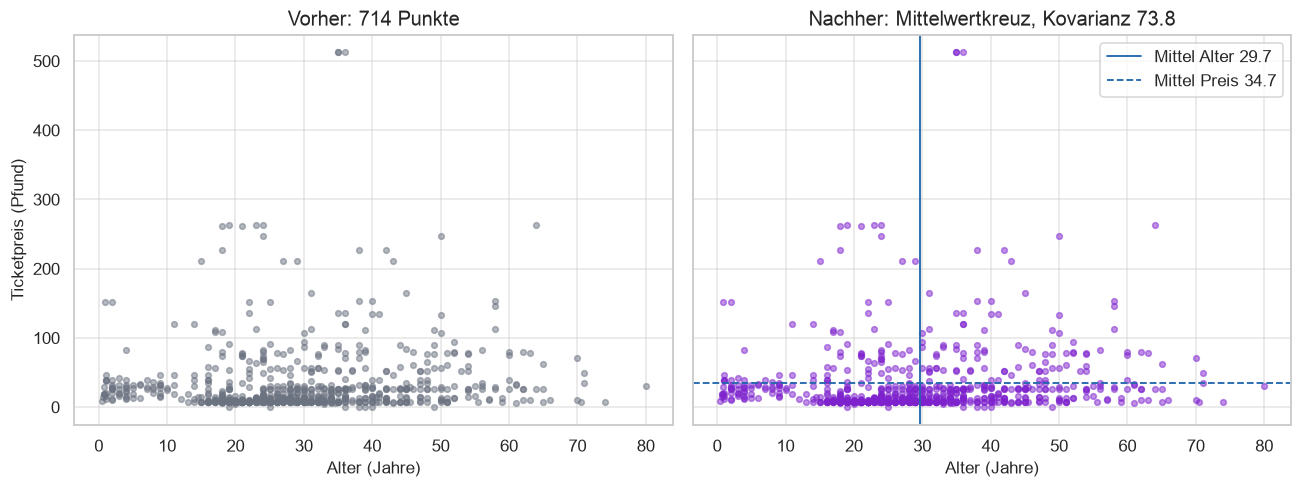

In [9]:
# Darstellen
fig, achsen = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
achsen[0].scatter(alter, preis, s=14, color='#6B7280', alpha=0.5)
achsen[0].set(title='Vorher: 714 Punkte', xlabel='Alter (Jahre)', ylabel='Ticketpreis (Pfund)')

achsen[1].scatter(alter, preis, s=14, color='#7E22CE', alpha=0.5)
achsen[1].axvline(alter.mean(), color='#2166AC', linewidth=1.2, label=f'Mittel Alter {alter.mean():.1f}')
achsen[1].axhline(preis.mean(), color='#2166AC', linewidth=1.2, linestyle='--',
                  label=f'Mittel Preis {preis.mean():.1f}')
achsen[1].set(title=f'Nachher: Mittelwertkreuz, Kovarianz {alter.cov(preis):.1f}',
              xlabel='Alter (Jahre)')
achsen[1].legend(loc='upper right')
plt.tight_layout()
plt.show()

**Bedeutung.** Von Hand 3.33, pandas 3.33, NumPy 3.33: Alle teilen durch $n - 1$, wie `.var()` in NB02; die Nennerfrage stellt sich hier nicht neu. Bei den Passagieren überwiegen die positiven Produkte (408 gegen 306) und auch ihre Summe (141 120 gegen 88 465), die Kovarianz ist positiv: 73.85 Jahre·Pfund. Ob das viel ist, lässt sich an der Zahl nicht ablesen, denn sie trägt die Einheiten beider Variablen. Das ist das Problem des nächsten Unterabschnitts.

> **Euer Datensatz.** Welche Einheit hätte die Kovarianz eures Paars? Könnt ihr mit dieser Zahl jemandem die Stärke des Zusammenhangs erklären?

### 2.2 Die Einheit kürzt sich weg: Pearson r

**Problem.** Der Ticketpreis in Pence statt in Pfund: dieselben 714 Passagiere, dieselbe Wolke, aber die Kovarianz springt von 73.85 auf 7385. Welche Zahl beschreibt den Zusammenhang unabhängig von der Einheit, und was sagt sie über Alter und Preis?

**Theorie.** *Vorlesung: Folien «Die Kovarianz hängt an der Einheit», «Pearson r ist die standardisierte Kovarianz», «r in Worten»*

$$r = \frac{\text{Cov}(X,Y)}{s_X\, s_Y}$$

Die Kovarianz trägt die Einheiten beider Variablen; mit der Einheit ändert sich die Zahl, nicht der Zusammenhang. Teilt man durch beide Standardabweichungen, kürzen sich die Einheiten weg: $r$ liegt immer zwischen $-1$ und $+1$, ist symmetrisch in $x$ und $y$ und misst die Enge um eine Gerade. Anschaulich: Beide Variablen standardisieren, $z = (x - \bar{x}) / s$, dann ist $r$ die Kovarianz der z-Werte. Für Worte gibt es eine Faustregel nach dem Betrag: unter 0.2 keiner, 0.2 bis 0.4 schwach, 0.4 bis 0.7 mittel, 0.7 bis 0.9 stark, über 0.9 sehr stark; das Vorzeichen gibt die Richtung. Sie gilt nur für gerade Wolken ohne Ausreisser.

**Code.** Die Kovarianz in Pfund und in Pence, dann $r$ von Hand als Cov/(s_x·s_y) und als Kovarianz der z-Werte, Gegenprobe mit `.corr()`. Vorher die rohe Wolke, nachher die standardisierte.

In [10]:
# Rechnen
preis_pence = preis * 100
print(f'Kovarianz in Pfund: {alter.cov(preis):.2f},  in Pence: {alter.cov(preis_pence):.2f}')

s_alter, s_preis = alter.std(ddof=1), preis.std(ddof=1)
r_hand = alter.cov(preis) / (s_alter * s_preis)
print(f'r von Hand: {alter.cov(preis):.2f} / ({s_alter:.2f} · {s_preis:.2f}) = {r_hand:.4f}')

z_alter = (alter - alter.mean()) / s_alter
z_preis = (preis - preis.mean()) / s_preis
print(f'Kovarianz der z-Werte: {z_alter.cov(z_preis):.4f}')
print(f'pandas alter.corr(preis): {alter.corr(preis):.4f},  in Pence: {alter.corr(preis_pence):.4f}')

Kovarianz in Pfund: 73.85,  in Pence: 7384.90
r von Hand: 73.85 / (14.53 · 52.92) = 0.0961
Kovarianz der z-Werte: 0.0961
pandas alter.corr(preis): 0.0961,  in Pence: 0.0961


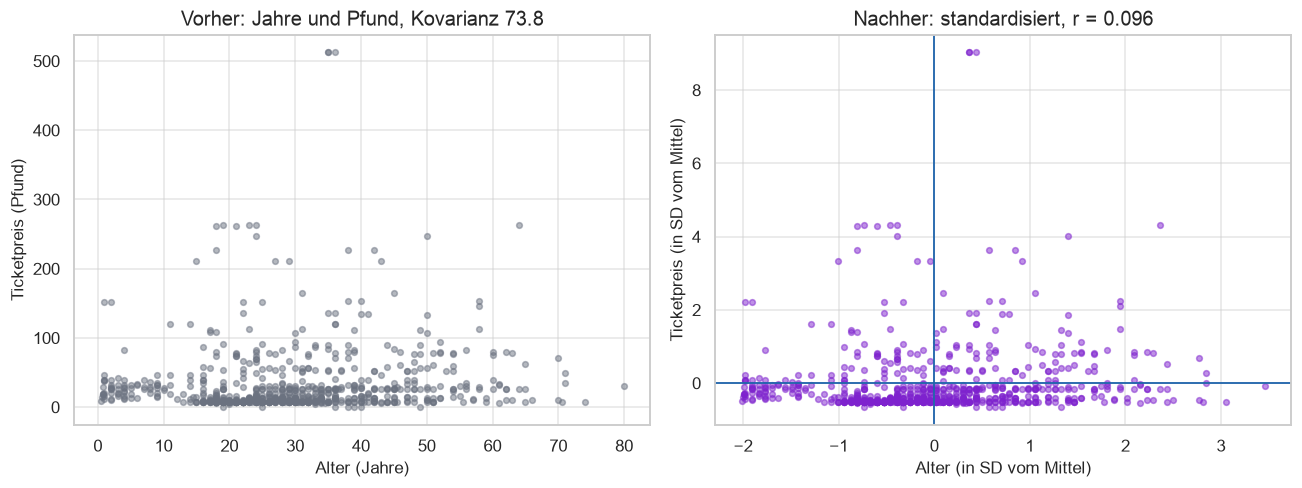

In [11]:
# Darstellen
fig, achsen = plt.subplots(1, 2, figsize=(12, 4.6))
achsen[0].scatter(alter, preis, s=14, color='#6B7280', alpha=0.5)
achsen[0].set(title=f'Vorher: Jahre und Pfund, Kovarianz {alter.cov(preis):.1f}',
              xlabel='Alter (Jahre)', ylabel='Ticketpreis (Pfund)')

achsen[1].scatter(z_alter, z_preis, s=14, color='#7E22CE', alpha=0.5)
achsen[1].axvline(0, color='#2166AC', linewidth=1.2)
achsen[1].axhline(0, color='#2166AC', linewidth=1.2)
achsen[1].set(title=f'Nachher: standardisiert, r = {alter.corr(preis):.3f}',
              xlabel='Alter (in SD vom Mittel)', ylabel='Ticketpreis (in SD vom Mittel)')
plt.tight_layout()
plt.show()

**Bedeutung.** Die Kovarianz wird in Pence 100-mal grösser, $r$ bleibt 0.096, von Hand wie mit `.corr()`: Die Einheiten sind weg, und erst damit ist die Zahl zwischen Datensätzen vergleichbar. Nach der Faustregel liegt 0.096 unter 0.2: praktisch kein linearer Zusammenhang. Ältere Passagiere haben nicht systematisch mehr bezahlt, so wie die Vorlesung es mit «etwa 0.1» angekündigt hat. Die rechte Wolke ist dieselbe wie die linke, nur die Achsen zählen in Standardabweichungen. Berichtet $r$ mit n und der Form der Wolke, nie die Kovarianz allein.

> **Euer Datensatz.** Berechnet r für euer Paar und übersetzt es mit der Faustregel in Worte. Dürft ihr die Faustregel überhaupt anwenden, also ist eure Wolke gerade und ohne Ausreisser?

### 2.3 Ein Punkt kann r kippen

**Problem.** Zehn simulierte Punkte liegen eng um eine Gerade, r = 0.99. Ein elfter Punkt weit rechts, unterhalb der Geraden, drückt r auf 0.69. Darf man ihn löschen?

**Theorie.** *Vorlesung: Folien «Pearson braucht eine gerade Wolke», «Ein Punkt kann r kippen»*

Pearson $r$ braucht drei Bedingungen: beide Variablen metrisch, der Zusammenhang ungefähr linear, keine starken Ausreisser. $r$ beruht auf Mittelwerten und Standardabweichungen und reagiert auf Ausreisser wie der Mittelwert in VL02; ein einziger Punkt kann es deutlich verschieben. Vor dem Rechnen deshalb plotten und eine Ausreisserregel anwenden, etwa die Tukey-Zäune aus VL03. Einen auffälligen Punkt löscht man nie ungeprüft: Man klärt, ob er ein Fehler ist oder echt. Rangmasse sind robuster und dienen als Gegenprobe.

**Code.** $r$ mit und ohne den elften Punkt, die Tukey-Zäune für x und y, und Spearman als Gegenprobe, ein Vorgriff auf Kapitel 3. Vorher die elf Punkte mit einem einzigen $r$, nachher der Punkt markiert, mit beiden Geraden und dem Zaun.

In [12]:
# Rechnen
x_zehn = np.linspace(1, 10, 10)
y_zehn = 2 + 1.5 * x_zehn + RNG.normal(0, 1.2, 10)
x_elf = np.append(x_zehn, 18.0)                  # ein Punkt weit rechts ...
y_elf = np.append(y_zehn, 12.0)                  # ... deutlich unter der Geraden

r_zehn, r_elf = np.corrcoef(x_zehn, y_zehn)[0, 1], np.corrcoef(x_elf, y_elf)[0, 1]
print(f'r ohne den Punkt: {r_zehn:.3f},  mit dem Punkt: {r_elf:.3f}')

q1_x, q3_x = np.quantile(x_elf, [0.25, 0.75]); zaun_x = q3_x + 1.5 * (q3_x - q1_x)
q1_y, q3_y = np.quantile(y_elf, [0.25, 0.75]); zaun_y = q3_y + 1.5 * (q3_y - q1_y)
print(f'Oberer Tukey-Zaun x: {zaun_x:.2f} (Punkt bei {x_elf[-1]:.0f}: '
      f'{"markiert" if x_elf[-1] > zaun_x else "nicht markiert"}), '
      f'y: {zaun_y:.2f} (Punkt bei {y_elf[-1]:.0f}: '
      f'{"markiert" if y_elf[-1] > zaun_y else "nicht markiert"})')

rho_zehn = pd.Series(x_zehn).corr(pd.Series(y_zehn), method='spearman')
rho_elf = pd.Series(x_elf).corr(pd.Series(y_elf), method='spearman')
print(f'Spearman als Gegenprobe: ohne {rho_zehn:.3f}, mit {rho_elf:.3f}')

r ohne den Punkt: 0.988,  mit dem Punkt: 0.687
Oberer Tukey-Zaun x: 16.00 (Punkt bei 18: markiert), y: 19.67 (Punkt bei 12: nicht markiert)
Spearman als Gegenprobe: ohne 0.988, mit 0.900


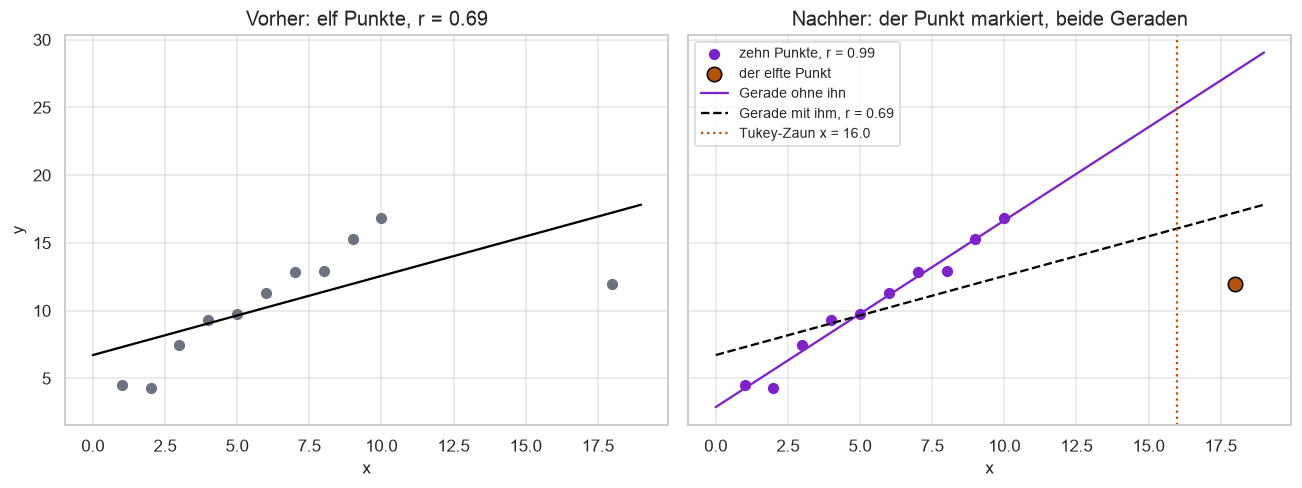

In [13]:
# Darstellen
gitter = np.linspace(0, 19, 50)
fig, achsen = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)

steigung, abschnitt = np.polyfit(x_elf, y_elf, 1)
achsen[0].scatter(x_elf, y_elf, s=40, color='#6B7280')
achsen[0].plot(gitter, abschnitt + steigung * gitter, color='black', linewidth=1.5)
achsen[0].set(title=f'Vorher: elf Punkte, r = {r_elf:.2f}', xlabel='x', ylabel='y')

steigung_z, abschnitt_z = np.polyfit(x_zehn, y_zehn, 1)
achsen[1].scatter(x_zehn, y_zehn, s=40, color='#7E22CE', label=f'zehn Punkte, r = {r_zehn:.2f}')
achsen[1].scatter(x_elf[-1], y_elf[-1], s=90, color='#B45309', edgecolor='black',
                  label='der elfte Punkt')
achsen[1].plot(gitter, abschnitt_z + steigung_z * gitter, color='#7E22CE', linewidth=1.5,
               label='Gerade ohne ihn')
achsen[1].plot(gitter, abschnitt + steigung * gitter, color='black', linewidth=1.5,
               linestyle='--', label=f'Gerade mit ihm, r = {r_elf:.2f}')
achsen[1].axvline(zaun_x, color='#B45309', linestyle=':', linewidth=1.5,
                  label=f'Tukey-Zaun x = {zaun_x:.1f}')
achsen[1].set(title='Nachher: der Punkt markiert, beide Geraden', xlabel='x')
achsen[1].legend(loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

**Bedeutung.** Ein einziger Punkt zieht $r$ von 0.988 auf 0.687 und die Gerade merklich flacher. Der Tukey-Zaun für x (16.0) markiert ihn, der für y (19.7) nicht: Ausreisser in zwei Dimensionen fallen oft nur in einer Richtung auf, manchmal in keiner, und dann sieht sie nur der Plot. Spearman fällt nur von 0.988 auf 0.900, weil die Ränge den Abstand nicht sehen, nur die Reihenfolge: Der Punkt ist rechts der Grösste, in y aber nur der Fünftgrösste. Die Entscheidung heisst prüfen, nicht löschen: Ist der Punkt ein Fehler (Tippfehler, falsche Einheit), wird er korrigiert oder dokumentiert entfernt; ist er echt, gehören in den Bericht beide $r$, mit und ohne, dazu das Rangmass und der Satz, warum der Punkt dort liegt.

> **Euer Datensatz.** Markieren die Tukey-Zäune aus NB03 in eurem Paar einen Punkt, in x oder in y? Wie stark ändert sich r ohne ihn, und was wisst ihr über diesen Fall?

> **Take-Home Kovarianz und Pearson r**
>
> 1. **Kovarianz** zählt gemeinsame Abweichungen, geteilt durch n − 1, und hängt an den Einheiten.
> 2. **Pearson r** ist die standardisierte Kovarianz: zwischen −1 und +1, ohne Einheit, misst Linearität.
> 3. **r in Worten** nur für gerade Wolken ohne Ausreisser; r = 0 schliesst eine Kurve nicht aus.
> 4. **Ein Punkt kann r kippen:** plotten, Zäune prüfen, nie ungeprüft löschen, Rangmass als Gegenprobe.
>
> Immer das Streudiagramm mitliefern.

---

## 3. Spearman und Kendall

*Vorlesung: Abschnitt «Spearman und Kendall». Leitfrage: Was tun, wenn die Wolke gekrümmt ist oder ein Ausreisser stört?*

Die Antwort der Vorlesung: Werte durch Ränge ersetzen. Spearman rechnet Pearson auf den Rängen, Kendall zählt geordnete Paare; beide messen Monotonie statt Linearität und sind robust gegen Ausreisser.

### 3.1 Spearman ist Pearson auf den Rängen

**Problem.** Drei Passagiere haben 512.33 Pfund bezahlt, der nächstteurere Preis liegt bei 263. Für $r$ zählt dieser Abstand voll. Was ändert sich, wenn nur die Reihenfolge zählt, und was macht pandas mit den 494 Preisen, die mehrfach vorkommen?

**Theorie.** *Vorlesung: Folien «Ränge statt Werte», «Spearman ist Pearson auf den Rängen», «Gleiche Werte teilen sich den Rang»*

Jeder Wert wird durch seinen Rang ersetzt, seine Position in der sortierten Reihe; der Milliardär ist dann nur noch «der Grösste». Gemessen wird, ob $x$ und $y$ in derselben Reihenfolge stehen, also Monotonie. Spearman $\rho$ ist Pearson $r$, gerechnet auf den Rängen. Ohne gleiche Werte gilt die Kurzformel

$$\rho = 1 - \frac{6\sum d_i^2}{n(n^2-1)}$$

mit $d_i$ als Differenz der beiden Ränge einer Beobachtung. Gleiche Werte (Ties) bekommen den mittleren Rang der Plätze, die sie belegen; dann ist die Kurzformel nur eine Näherung, und die Software rechnet Pearson auf den Rängen. Die Parallele zu VL02: Der Median schaut auf die Reihenfolge, der Mittelwert auf die Abstände; Spearman ist der Median unter den Korrelationen.

**Code.** Erst das Beispiel der Vorlesung: Kurzformel und Pearson auf den Rängen ergeben dasselbe. Dann Alter und Preis: `.rank()` mit dem mittleren Rang, die Kurzformel gegen `.corr(method='spearman')`. Vorher die Rohwerte, nachher die Ränge.

In [14]:
# Rechnen
x = pd.Series([2, 4, 6, 8, 10]); y = pd.Series([5, 7, 6, 9, 8])
rang_x, rang_y = x.rank(), y.rank()
d = rang_x - rang_y
print(pd.DataFrame({'x': x, 'Rang x': rang_x, 'y': y, 'Rang y': rang_y, 'd': d, 'd²': d ** 2}).to_string(index=False))

n = len(x)
rho_kurz = 1 - 6 * (d ** 2).sum() / (n * (n ** 2 - 1))
print(f'\nKurzformel: 1 - 6·{(d ** 2).sum():.0f} / ({n}·{n ** 2 - 1}) = {rho_kurz:.2f}')
print(f'Pearson auf den Rängen: {rang_x.corr(rang_y):.2f}')
print(f"pandas method='spearman': {x.corr(y, method='spearman'):.2f}")

 x  Rang x  y  Rang y    d  d²
 2     1.0  5     1.0  0.0 0.0
 4     2.0  7     3.0 -1.0 1.0
 6     3.0  6     2.0  1.0 1.0
 8     4.0  9     5.0 -1.0 1.0
10     5.0  8     4.0  1.0 1.0

Kurzformel: 1 - 6·4 / (5·24) = 0.80
Pearson auf den Rängen: 0.80
pandas method='spearman': 0.80


In [15]:
# Rechnen
rang_alter, rang_preis = alter.rank(), preis.rank()        # Ties bekommen den mittleren Rang
teuerste = preis.sort_values().tail(4)
print('Die vier teuersten Tickets und ihre Ränge:')
print(pd.DataFrame({'Preis': teuerste, 'Rang': rang_preis[teuerste.index]}).to_string())
print(f'\nMehrfach vorkommende Preise: {preis.duplicated().sum()}, Alter: {alter.duplicated().sum()}')

d = rang_alter - rang_preis
n = len(paare)
print(f'Kurzformel (nur ohne Ties exakt): {1 - 6 * (d ** 2).sum() / (n * (n ** 2 - 1)):.4f}')
print(f'Pearson auf den Rängen:           {rang_alter.corr(rang_preis):.4f}')
print(f"pandas method='spearman':         {alter.corr(preis, method='spearman'):.4f}")
print(f'zum Vergleich Pearson r:          {alter.corr(preis):.4f}')

Die vier teuersten Tickets und ihre Ränge:
        Preis   Rang
438  263.0000  709.5
679  512.3292  713.0
258  512.3292  713.0
737  512.3292  713.0

Mehrfach vorkommende Preise: 494, Alter: 626
Kurzformel (nur ohne Ties exakt): 0.1355
Pearson auf den Rängen:           0.1351
pandas method='spearman':         0.1351
zum Vergleich Pearson r:          0.0961


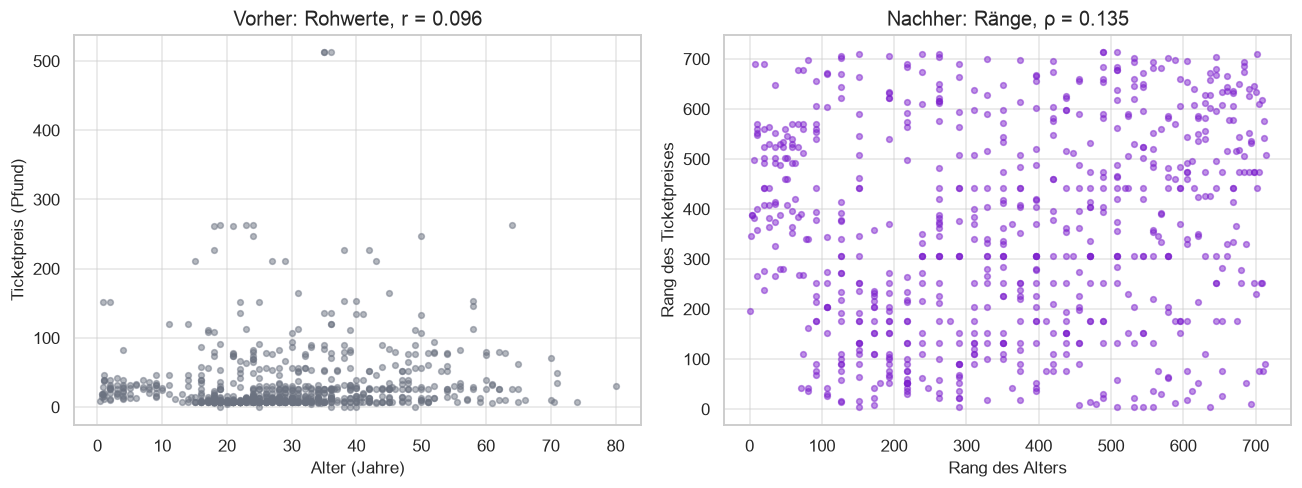

In [16]:
# Darstellen
fig, achsen = plt.subplots(1, 2, figsize=(12, 4.6))
achsen[0].scatter(alter, preis, s=14, color='#6B7280', alpha=0.5)
achsen[0].set(title=f'Vorher: Rohwerte, r = {alter.corr(preis):.3f}',
              xlabel='Alter (Jahre)', ylabel='Ticketpreis (Pfund)')

achsen[1].scatter(rang_alter, rang_preis, s=14, color='#7E22CE', alpha=0.5)
achsen[1].set(title=f"Nachher: Ränge, ρ = {alter.corr(preis, method='spearman'):.3f}",
              xlabel='Rang des Alters', ylabel='Rang des Ticketpreises')
plt.tight_layout()
plt.show()

**Bedeutung.** Im Beispiel der Vorlesung stimmen Kurzformel, Pearson auf den Rängen und `method='spearman'` überein: 0.8. Bei den Passagieren bekommen die drei Tickets zu 512.33 Pfund denselben mittleren Rang 713 (die Plätze 712 bis 714 geteilt), und der Abstand zu 263 Pfund ist verschwunden; rechts ist aus dem langen Tail ein gleichmässiges Band geworden. Mit 494 mehrfachen Preisen und 626 mehrfachen Altersangaben weicht die Kurzformel (0.1355) vom exakten Wert ab (0.1351); pandas rechnet exakt. Die Entscheidung: Alter und Preis haben weder einen linearen (r = 0.096) noch einen monotonen Zusammenhang (ρ = 0.135), beide unter 0.2. Im Bericht steht das gewählte Mass mit Namen, dem Grund und n.

> **Euer Datensatz.** Welche eurer Variablen hat Ausreisser oder viele gleiche Werte? Rechnet r und ρ mit `method=` und entscheidet, welches Mass ihr berichtet und warum.

### 3.2 Kendall zählt geordnete Paare

**Problem.** Die Klasse (1, 2, 3) ist ordinal: 891 Passagiere teilen sich drei Werte. Pearson liefert für Klasse und Preis −0.55, als wären die Abstände zwischen den Klassen gleich. Welches Mass passt für eine Ordinalskala mit so vielen Ties?

**Theorie.** *Vorlesung: Folien «Kendall zählt geordnete Paare», «Die Form wählt das Mass», «Spearman und Kendall»*

$$\tau = \frac{n_k - n_d}{\tfrac12 n(n-1)}$$

Kendall $\tau$ schaut jedes Paar von Beobachtungen an: gleiche Reihenfolge in $x$ und $y$ heisst konkordant, umgekehrte heisst diskordant. $\tau$ ist die Zahl der konkordanten minus die der diskordanten Paare, geteilt durch alle Paare; alle konkordant ergibt $+1$, alle diskordant $-1$. Das Beispiel der Vorlesung: $X = (2, 4, 6, 8, 10)$, $Y = (5, 7, 6, 9, 8)$ bilden zehn Paare, zwei davon laufen gegen die Richtung (Beobachtungen 2 und 3, 4 und 5), also $\tau = (8 - 2)/10 = 0.6$, während $\rho$ für dieselben Punkte 0.8 ergibt: $\tau$ fällt meist kleiner aus als $\rho$, beide messen Monotonie. Kendall ist stabiler bei kleinem $n$ und vielen Ties; für ordinale Variablen wie Noten oder Likert-Skalen nimmt man Spearman oder Kendall.

**Code.** Klasse und Preis mit allen drei Massen über `method=`; pandas rechnet bei `method='kendall'` Kendalls tau-b, das die Ties berücksichtigt. Dazu die Zahl der Paare, die dieselbe Klasse haben und deshalb weder konkordant noch diskordant sind. Vorher die Klasse als Zahl mit einer Geraden, nachher als Stufen mit den Rängen des Preises je Klasse.

In [17]:
# Rechnen
klasse_preis = titanic[['pclass', 'fare']]
n = len(klasse_preis)
je_klasse = klasse_preis['pclass'].value_counts().sort_index()
print(f"Werte der Klasse: {list(je_klasse.index)}, Passagiere je Klasse: {list(je_klasse)}, n = {n}")

alle_paare = n * (n - 1) // 2
gleiche_klasse = int((je_klasse * (je_klasse - 1) // 2).sum())
print(f'Paare insgesamt: {alle_paare}, davon mit derselben Klasse (weder konkordant noch diskordant): '
      f'{gleiche_klasse} ({gleiche_klasse / alle_paare:.0%})')

masse = pd.Series({methode: klasse_preis.corr(method=methode).iloc[0, 1]
                   for methode in ['pearson', 'spearman', 'kendall']})
print(masse.round(3).to_string())

Werte der Klasse: [1, 2, 3], Passagiere je Klasse: [216, 184, 491], n = 891
Paare insgesamt: 396495, davon mit derselben Klasse (weder konkordant noch diskordant): 160351 (40%)
pearson    -0.549
spearman   -0.688
kendall    -0.574


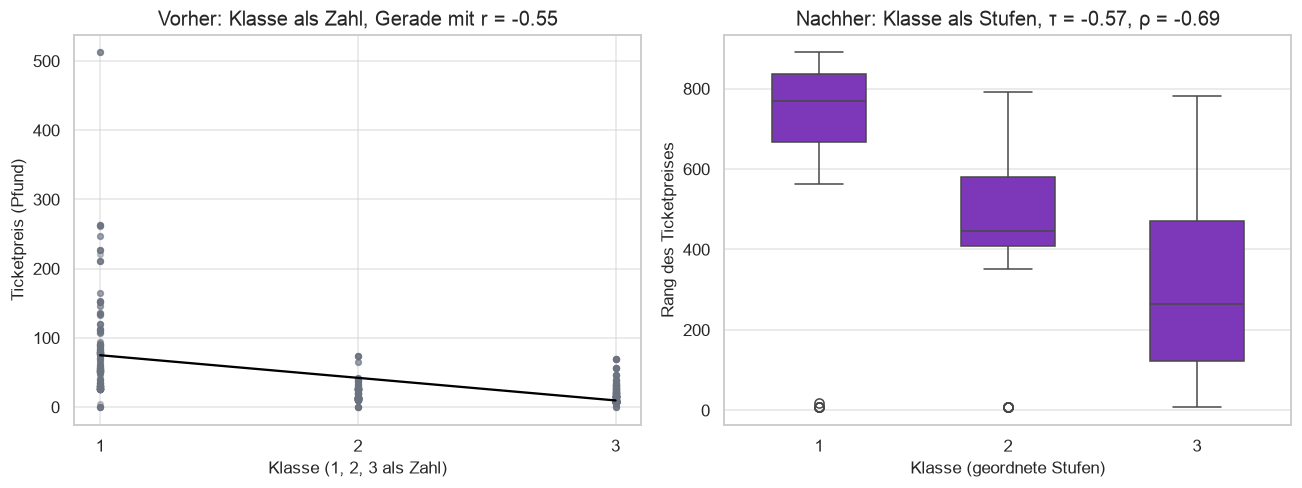

In [18]:
# Darstellen
fig, achsen = plt.subplots(1, 2, figsize=(12, 4.6))
achsen[0].scatter(klasse_preis['pclass'], klasse_preis['fare'], s=14, color='#6B7280', alpha=0.4)
steigung, abschnitt = np.polyfit(klasse_preis['pclass'], klasse_preis['fare'], 1)
achsen[0].plot([1, 3], [abschnitt + steigung * 1, abschnitt + steigung * 3], color='black', linewidth=1.5)
achsen[0].set(title=f"Vorher: Klasse als Zahl, Gerade mit r = {masse['pearson']:.2f}",
              xlabel='Klasse (1, 2, 3 als Zahl)', ylabel='Ticketpreis (Pfund)', xticks=[1, 2, 3])

rang_preis_alle = klasse_preis['fare'].rank()
sns.boxplot(x=klasse_preis['pclass'], y=rang_preis_alle, color='#7E22CE', width=0.5, ax=achsen[1])
achsen[1].set(title=f"Nachher: Klasse als Stufen, τ = {masse['kendall']:.2f}, ρ = {masse['spearman']:.2f}",
              xlabel='Klasse (geordnete Stufen)', ylabel='Rang des Ticketpreises')
plt.tight_layout()
plt.show()

**Bedeutung.** Alle drei Masse sind negativ, je höher die Klassennummer, desto billiger: r −0.55, ρ −0.69, τ −0.57. Pearson tut so, als lägen zwischen den Klassen 1, 2 und 3 gleiche Abstände in Pfund und als führe eine Gerade durch drei Säulen; das gibt die Skala nicht her. Rechts stehen die Klassen als Stufen, und die Ränge des Preises fallen von Stufe zu Stufe; mehr sieht ein Rangmass nicht, mehr braucht es nicht. 40 Prozent aller Paare haben dieselbe Klasse und zählen für $\tau$ weder als konkordant noch als diskordant, deshalb rechnet pandas tau-b, das diese Ties im Nenner berücksichtigt. Für eine ordinale Variable berichtet ihr ein Rangmass und nennt es beim Namen; bei wenigen Stufen und vielen Ties ist Kendall die stabilere Wahl.

> **Euer Datensatz.** Habt ihr eine ordinale Variable (Noten, Stufen, Likert-Skala)? Wie viele verschiedene Werte hat sie, und welches Mass berichtet ihr dafür?

### 3.3 Die Form wählt das Mass

**Problem.** Drei Formen: Flossenlänge und Gewicht der Pinguine (eine gerade Wolke), die Kurve $y = e^{x/2}$ aus der Vorlesung (monoton, gekrümmt) und ein simuliertes U. Welches Mass sieht welchen Zusammenhang, und welches sieht keinen?

**Theorie.** *Vorlesung: Folien «Die Form wählt das Mass», «r = 0 heisst: keine Gerade», «Echte Daten: die Zufriedenheitskurve»*

Bei einer linearen Form sind $r$, $\rho$ und $\tau$ alle hoch. Bei einer monoton gekrümmten Form sind $\rho$ und $\tau$ hoch, $r$ kleiner: Die Reihenfolge stimmt perfekt, die Gerade nicht; für $y = e^{x/2}$ gilt $\rho = 1$ und $r \approx 0.87$. Bei einem U liegen alle drei nahe 0, obwohl der Zusammenhang perfekt sein kann: $r = 0$ heisst nur, dass keine Gerade passt. Ein U ist für alle drei Masse unsichtbar; die Vorlesung zeigt es an der Zufriedenheitskurve und rät: am Tiefpunkt teilen und jeden Abschnitt getrennt rechnen.

**Code.** $r$, $\rho$ und $\tau$ für die drei Formen in einer Tabelle, dann das U am Tiefpunkt geteilt. Vorher die drei Wolken ohne Zahlen, nachher mit allen drei Massen.

In [19]:
# Rechnen
flossen = penguins[['flipper_length_mm', 'body_mass_g']].dropna()
x_mono = np.linspace(1, 10, 40); y_mono = np.exp(x_mono / 2)                # Beispiel der Vorlesung
x_u = np.linspace(-3, 3, 40);    y_u = x_u ** 2 + RNG.normal(0, 0.8, 40)     # U mit etwas Rauschen

formen = {'linear (Flossen, Gewicht)': (flossen['flipper_length_mm'], flossen['body_mass_g']),
          'monoton gekrümmt (e^(x/2))': (pd.Series(x_mono), pd.Series(y_mono)),
          'U-förmig': (pd.Series(x_u), pd.Series(y_u))}
tabelle = pd.DataFrame({name: {m: x.corr(y, method=m) for m in ['pearson', 'spearman', 'kendall']}
                        for name, (x, y) in formen.items()}).T
print(tabelle.round(3).to_string())

links, rechts = x_u < 0, x_u > 0
print(f"\nU am Tiefpunkt geteilt: links ρ = {pd.Series(x_u[links]).corr(pd.Series(y_u[links]), method='spearman'):.2f}, "
      f"rechts ρ = {pd.Series(x_u[rechts]).corr(pd.Series(y_u[rechts]), method='spearman'):.2f}")

                            pearson  spearman  kendall
linear (Flossen, Gewicht)     0.871     0.840    0.660
monoton gekrümmt (e^(x/2))    0.874     1.000    1.000
U-förmig                     -0.044    -0.051   -0.056

U am Tiefpunkt geteilt: links ρ = -0.97, rechts ρ = 0.93


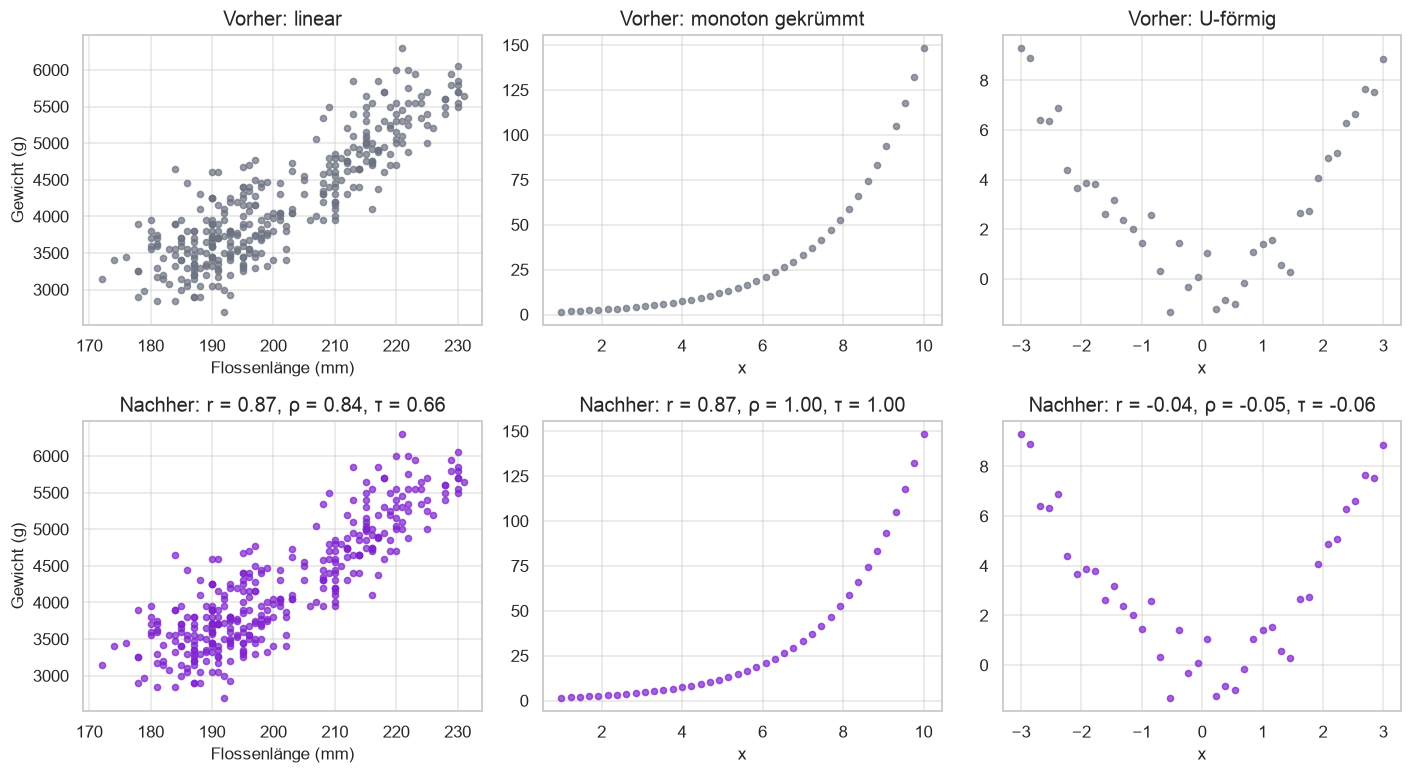

In [20]:
# Darstellen
fig, achsen = plt.subplots(2, 3, figsize=(13, 7.2))
for spalte, (name, (x, y)) in enumerate(formen.items()):
    achsen[0, spalte].scatter(x, y, s=16, color='#6B7280', alpha=0.7)
    achsen[0, spalte].set(title=f'Vorher: {name.split(" (")[0]}', xlabel='x', ylabel='y' if spalte == 0 else '')
    achsen[1, spalte].scatter(x, y, s=16, color='#7E22CE', alpha=0.7)
    zeile = tabelle.loc[name]
    achsen[1, spalte].set(title=f'Nachher: r = {zeile["pearson"]:.2f}, ρ = {zeile["spearman"]:.2f}, '
                                f'τ = {zeile["kendall"]:.2f}', xlabel='x', ylabel='y' if spalte == 0 else '')
achsen[0, 0].set(xlabel='Flossenlänge (mm)', ylabel='Gewicht (g)')
achsen[1, 0].set(xlabel='Flossenlänge (mm)', ylabel='Gewicht (g)')
plt.tight_layout()
plt.show()

**Bedeutung.** Die Pinguine sind der lineare Fall: r 0.87, ρ 0.84, τ 0.66, alle hoch, und $r$ ist am höchsten. Die Kurve ist streng monoton: ρ = 1 und τ = 1, weil die Reihenfolge perfekt stimmt, r = 0.87 wie in der Vorlesung, weil keine Gerade passt. Das U sieht keines der drei Masse: alle liegen bei 0, obwohl $y$ vollständig von $x$ abhängt. Am Tiefpunkt geteilt wird es sichtbar, links ρ = −0.97, rechts 0.93. Ein Rangmass rettet also einen gekrümmten, nicht aber einen nicht monotonen Zusammenhang; den sieht nur der Plot.

> **Euer Datensatz.** Zeigt eure Wolke ein U oder einen Knick? Wo würdet ihr teilen, und was berichtet ihr je Abschnitt?

> **Take-Home Spearman und Kendall**
>
> 1. **Ränge** messen Monotonie und sind robust gegen Ausreisser: Der Grösste ist nur noch der Grösste.
> 2. **Spearman** ist Pearson auf den Rängen; Ties bekommen den mittleren Rang, die Kurzformel ist dann nur eine Näherung.
> 3. **Kendall** zählt konkordante und diskordante Paare, stabil bei kleinem n und vielen Ties.
> 4. **Die Form wählt das Mass:** linear alle hoch, monoton gekrümmt ρ und τ hoch, U alle nahe 0.
>
> Ordinale Variablen bekommen ein Rangmass, und das Mass steht mit Namen im Bericht.

---

## 4. Zusammenhang und Ursache

*Vorlesung: Abschnitt «Zusammenhang und Ursache». Leitfrage: Was dürfen wir aus einer Korrelation schliessen?*

Messen können wir jetzt. Die Störche, die Schokolade und Berkeley zeigen, was schiefgeht, wenn man aus der Zahl eine Ursache macht. Drei Mechanismen werden hier mit bekannter Wahrheit nachgebaut oder in echten Daten gezeigt: die Drittvariable, der gemeinsame Trend und das Simpson-Paradox.

### 4.1 Eine Drittvariable erzeugt den Zusammenhang

**Problem.** 120 simulierte Sommertage: Eisverkauf und Badeunfälle korrelieren mit r = 0.52, obwohl in der Simulation der Eisverkauf keinerlei Wirkung auf die Unfälle hat. Woher kommt r, und wie weist man das in den Daten nach?

**Theorie.** *Vorlesung: Folien «Bringt der Storch die Babys?», «Eine Drittvariable erzeugt den Zusammenhang»*

Eine Drittvariable $Z$ beeinflusst $x$ und $y$ zugleich: Dann korrelieren $x$ und $y$, ohne dass $x$ auf $y$ wirkt. Das heisst Konfundierung, die Korrelation ist eine Scheinkorrelation. Bei den Störchen ist $Z$ die Landesfläche, bei Eis und Badeunfällen die Temperatur. Eine kausale Aussage braucht drei Dinge: die zeitliche Reihenfolge, geprüfte Drittvariablen und einen geeigneten Nachweis, am besten ein Experiment. Die einfachste Kontrolle von $Z$: die Daten nach $Z$ aufteilen und schauen, ob die Korrelation innerhalb der Gruppen bleibt.

**Code.** Bekannte Wahrheit: Die Temperatur $Z$ treibt beide Grössen, $x$ wirkt nicht auf $y$. Erst $r$ über alle Tage, dann $Z$ mit `pd.cut` in vier Bereiche geteilt und $r$ innerhalb jedes Bereichs. Vorher eine graue Wolke, nachher nach Temperatur gefärbt.

In [21]:
# Rechnen
tage = 120
temperatur = RNG.uniform(10, 32, tage)                              # Z
eisverkauf = 50 + 8 * temperatur + RNG.normal(0, 40, tage)          # x hängt nur an Z
badeunfaelle = 2 + 0.3 * temperatur + RNG.normal(0, 2, tage)        # y hängt nur an Z, nicht an x
sommer = pd.DataFrame({'temperatur': temperatur, 'eis': eisverkauf, 'unfaelle': badeunfaelle})

print(f"r(Eis, Unfälle) über alle Tage: {sommer['eis'].corr(sommer['unfaelle']):.2f}")
print(f"r(Temperatur, Eis) {sommer['temperatur'].corr(sommer['eis']):.2f}, "
      f"r(Temperatur, Unfälle) {sommer['temperatur'].corr(sommer['unfaelle']):.2f}")

sommer['bereich'] = pd.cut(sommer['temperatur'], bins=[10, 15.5, 21, 26.5, 32])
je_bereich = sommer.groupby('bereich', observed=True).apply(
    lambda g: pd.Series({'n': len(g), 'r': g['eis'].corr(g['unfaelle'])}), include_groups=False)
print('\nInnerhalb der Temperaturbereiche:')
print(je_bereich.round(2).to_string())

r(Eis, Unfälle) über alle Tage: 0.52
r(Temperatur, Eis) 0.81, r(Temperatur, Unfälle) 0.70

Innerhalb der Temperaturbereiche:
                 n     r
bereich                 
(10.0, 15.5]  32.0 -0.09
(15.5, 21.0]  25.0  0.08
(21.0, 26.5]  37.0  0.07
(26.5, 32.0]  26.0 -0.07


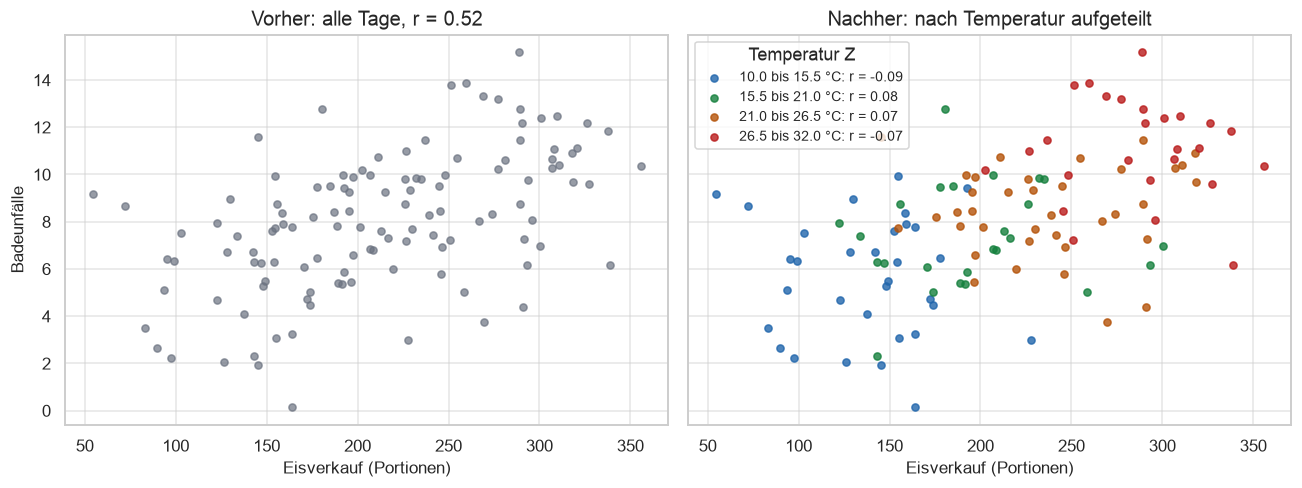

In [22]:
# Darstellen
farben_bereich = ['#2166AC', '#15803D', '#B45309', '#B91C1C']
fig, achsen = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
achsen[0].scatter(sommer['eis'], sommer['unfaelle'], s=22, color='#6B7280', alpha=0.7)
achsen[0].set(title=f"Vorher: alle Tage, r = {sommer['eis'].corr(sommer['unfaelle']):.2f}",
              xlabel='Eisverkauf (Portionen)', ylabel='Badeunfälle')

for farbe, (bereich, gruppe) in zip(farben_bereich, sommer.groupby('bereich', observed=True)):
    achsen[1].scatter(gruppe['eis'], gruppe['unfaelle'], s=22, color=farbe, alpha=0.8,
                      label=f'{bereich.left:.1f} bis {bereich.right:.1f} °C: r = {je_bereich.loc[bereich, "r"]:.2f}')
achsen[1].set(title='Nachher: nach Temperatur aufgeteilt', xlabel='Eisverkauf (Portionen)')
achsen[1].legend(loc='upper left', fontsize=9, title='Temperatur Z')
plt.tight_layout()
plt.show()

**Bedeutung.** Über alle Tage ist r = 0.52, ein mittlerer Zusammenhang, der in der Simulation gar nicht existiert: Beide Grössen hängen an der Temperatur (r 0.81 und 0.70 mit Z). Innerhalb der vier Temperaturbereiche bleibt nichts übrig, r liegt zwischen −0.09 und 0.08. Rechts sieht man den Grund: Die farbigen Teilwolken liegen gestaffelt, jede für sich ist formlos. Das Aufteilen nach Z ist die einfachste Kontrolle einer Drittvariable; sie funktioniert nur, wenn Z im Datensatz steht. Die rechnerische Kontrolle mit der Regression kommt in VL11.

> **Euer Datensatz.** Welche Drittvariable könnte euer wichtigstes Paar gemeinsam treiben: Zeit, Grösse einer Einheit, Alter, Region? Habt ihr sie im Datensatz, und bleibt r innerhalb ihrer Gruppen?

### 4.2 Gemeinsame Trends täuschen

**Problem.** Zwei simulierte Jahresreihen über 30 Jahre, beide wachsen, r = 0.97. Die Schwankungen um den Trend wurden für beide Reihen unabhängig gezogen. Was bleibt vom Zusammenhang, wenn man den Trend entfernt?

**Theorie.** *Vorlesung: Folie «Gemeinsame Trends täuschen»*

Zwei Reihen, die beide über die Zeit wachsen, korrelieren fast immer, auch wenn sie nichts miteinander zu tun haben: Die gemeinsame Ursache ist die Zeit. Die Prüfung: die Korrelation der Veränderungen von Jahr zu Jahr rechnen. Bleibt dort nichts übrig, war es nur der Trend.

**Code.** $r$ der Jahreswerte, dann `.diff()` und $r$ der Veränderungen. Vorher die Jahreswerte gegeneinander, nachher die Differenzen.

In [23]:
# Rechnen
jahre = np.arange(1995, 2025)
reihe_a = 1000 + 60 * (jahre - 1995) + RNG.normal(0, 80, len(jahre))   # z. B. Streaming-Abos
reihe_b = 20 + 3.5 * (jahre - 1995) + RNG.normal(0, 6, len(jahre))     # z. B. E-Bike-Verkäufe
trend = pd.DataFrame({'jahr': jahre, 'a': reihe_a, 'b': reihe_b})
trend['a_diff'] = trend['a'].diff()
trend['b_diff'] = trend['b'].diff()

print(f"r der Jahreswerte:    {trend['a'].corr(trend['b']):.3f}  (n = {len(trend)})")
print(f"r der Veränderungen:  {trend['a_diff'].corr(trend['b_diff']):.3f}  (n = {trend['a_diff'].notna().sum()}, "
      f"das erste Jahr hat keine Veränderung)")

r der Jahreswerte:    0.974  (n = 30)
r der Veränderungen:  -0.189  (n = 29, das erste Jahr hat keine Veränderung)


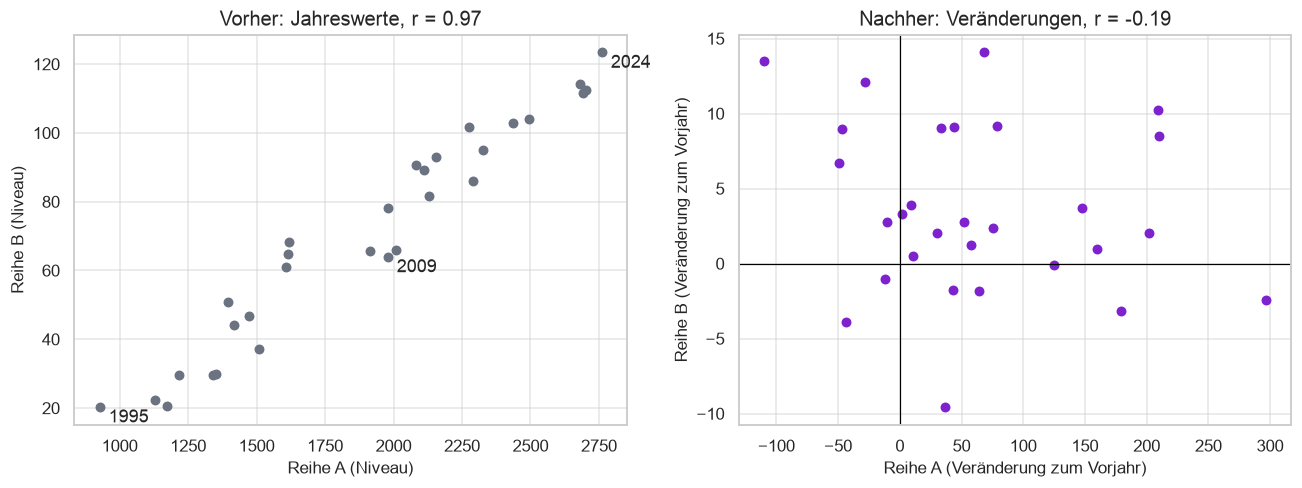

In [24]:
# Darstellen
fig, achsen = plt.subplots(1, 2, figsize=(12, 4.6))
achsen[0].scatter(trend['a'], trend['b'], s=30, color='#6B7280')
for _, zeile in trend.iloc[[0, 14, 29]].iterrows():
    achsen[0].annotate(f'{zeile.jahr:.0f}', (zeile.a, zeile.b), textcoords='offset points', xytext=(6, -10))
achsen[0].set(title=f"Vorher: Jahreswerte, r = {trend['a'].corr(trend['b']):.2f}",
              xlabel='Reihe A (Niveau)', ylabel='Reihe B (Niveau)')

achsen[1].scatter(trend['a_diff'], trend['b_diff'], s=30, color='#7E22CE')
achsen[1].axvline(0, color='black', linewidth=0.8); achsen[1].axhline(0, color='black', linewidth=0.8)
achsen[1].set(title=f"Nachher: Veränderungen, r = {trend['a_diff'].corr(trend['b_diff']):.2f}",
              xlabel='Reihe A (Veränderung zum Vorjahr)', ylabel='Reihe B (Veränderung zum Vorjahr)')
plt.tight_layout()
plt.show()

**Bedeutung.** Die Jahreswerte korrelieren mit 0.97, «sehr stark» nach der Faustregel, und die Punkte wandern von 1995 bis 2024 geordnet nach rechts oben: Das ist die Zeit, nicht ein Zusammenhang. Die Veränderungen korrelieren mit −0.19, bei 29 Differenzen ein Wert im Rauschen, so wie es die Simulation angelegt hat. Bevor ihr zwei Zeitreihen korreliert, bildet die Differenzen; und wer in einem Bericht nur die 0.97 zeigt, hat die Drittvariable Zeit übersehen.

> **Euer Datensatz.** Sind eure Variablen Zeitreihen oder hängen beide an einem Datum? Rechnet r der Veränderungen, bevor ihr r der Niveaus berichtet.

### 4.3 Simpson: das Aggregat dreht den Trend

**Problem.** Schnabellänge gegen Schnabeltiefe über alle 342 Pinguine: r = −0.24, längere Schnäbel sind flacher. Gilt das auch innerhalb jeder Art?

**Theorie.** *Vorlesung: Folien «Simpson: das Aggregat dreht den Trend», «Berkeley 1973: Frauen scheinbar benachteiligt», «Berkeley 1973: die Departemente erklären es»*

In jeder Gruppe steigt $y$ mit $x$; legt man die Gruppen zusammen, fällt $y$ mit $x$. Das Aggregat kann einen Trend umkehren, weil die Gruppen verschieden gross und verschieden gelagert sind; was fehlt, ist die Gruppenzugehörigkeit, also die Drittvariable. Berkeley 1973 ist dasselbe mit Quoten: 44 Prozent der Männer, 35 Prozent der Frauen zugelassen, doch innerhalb der Departemente meist kein Nachteil der Frauen. Sie bewarben sich häufiger bei Departementen mit niedriger Quote; das Departement ist die Drittvariable. Die Gesamtquote ist dabei die Summe der Zugelassenen durch die Summe der Bewerbungen, nicht der Mittelwert der Gruppenquoten.

**Code.** $r$ über alle Pinguine und je Art mit `groupby`, dann dasselbe Muster mit Quoten: die sechs Berkeley-Departemente der Vorlesung, die Gesamtquote aus den Zeilen. Vorher eine Regressionslinie durch alle Punkte (`regplot`), nachher eine je Art (`lmplot` mit `hue`).

In [25]:
# Rechnen
schnabel = penguins[['bill_length_mm', 'bill_depth_mm', 'species']].dropna()
print(f"Alle {len(schnabel)} Pinguine: r = {schnabel['bill_length_mm'].corr(schnabel['bill_depth_mm']):.3f}")

je_art = schnabel.groupby('species').apply(
    lambda g: pd.Series({'n': len(g), 'Länge (Mittel)': g['bill_length_mm'].mean(),
                         'Tiefe (Mittel)': g['bill_depth_mm'].mean(),
                         'r': g['bill_length_mm'].corr(g['bill_depth_mm'])}), include_groups=False)
print(je_art.round(2).to_string())

Alle 342 Pinguine: r = -0.235
               n  Länge (Mittel)  Tiefe (Mittel)     r
species                                               
Adelie     151.0           38.79           18.35  0.39
Chinstrap   68.0           48.83           18.42  0.65
Gentoo     123.0           47.50           14.98  0.64


In [26]:
# Rechnen
# Berkeley 1973, die sechs grössten Departemente (Folie «Berkeley 1973: die Departemente erklären es»)
berkeley = pd.DataFrame({
    'dept': list('ABCDEF'),
    'm_bewerbungen': [825, 560, 325, 417, 191, 373], 'm_quote': [62, 63, 37, 33, 28, 6],
    'f_bewerbungen': [108, 25, 593, 375, 393, 341],  'f_quote': [82, 68, 34, 35, 24, 7],
}).set_index('dept')
berkeley['m_zugelassen'] = berkeley['m_bewerbungen'] * berkeley['m_quote'] / 100
berkeley['f_zugelassen'] = berkeley['f_bewerbungen'] * berkeley['f_quote'] / 100
berkeley['Frauen vorn'] = berkeley['f_quote'] > berkeley['m_quote']
print(berkeley[['m_bewerbungen', 'm_quote', 'f_bewerbungen', 'f_quote', 'Frauen vorn']].to_string())

gesamt_m = berkeley['m_zugelassen'].sum() / berkeley['m_bewerbungen'].sum()
gesamt_f = berkeley['f_zugelassen'].sum() / berkeley['f_bewerbungen'].sum()
print(f'\nGesamtquote (Summe / Summe):  Männer {gesamt_m:.1%}, Frauen {gesamt_f:.1%}')
print(f"Mittelwert der Quoten (falsch): Männer {berkeley['m_quote'].mean():.1f} %, Frauen {berkeley['f_quote'].mean():.1f} %")
print(f"Frauen in den Departementen C bis F: {berkeley.loc['C':'F', 'f_bewerbungen'].sum() / berkeley['f_bewerbungen'].sum():.0%} "
      f"ihrer Bewerbungen, Männer: {berkeley.loc['C':'F', 'm_bewerbungen'].sum() / berkeley['m_bewerbungen'].sum():.0%}")

      m_bewerbungen  m_quote  f_bewerbungen  f_quote  Frauen vorn
dept                                                             
A               825       62            108       82         True
B               560       63             25       68         True
C               325       37            593       34        False
D               417       33            375       35         True
E               191       28            393       24        False
F               373        6            341        7         True

Gesamtquote (Summe / Summe):  Männer 44.5%, Frauen 30.3%
Mittelwert der Quoten (falsch): Männer 38.2 %, Frauen 41.7 %
Frauen in den Departementen C bis F: 93% ihrer Bewerbungen, Männer: 49%


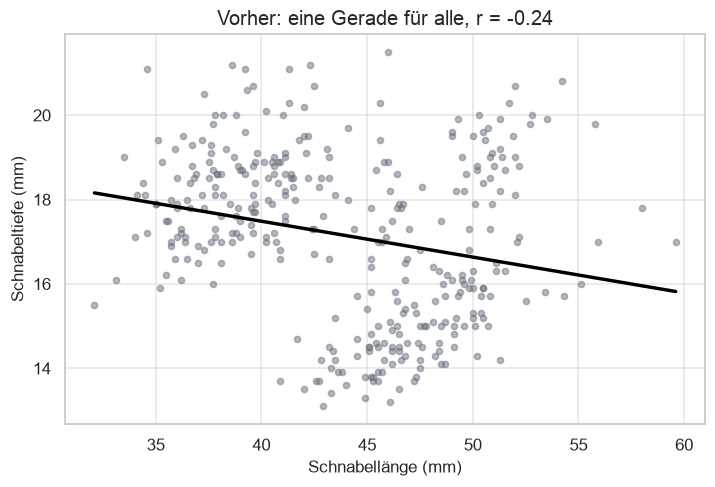

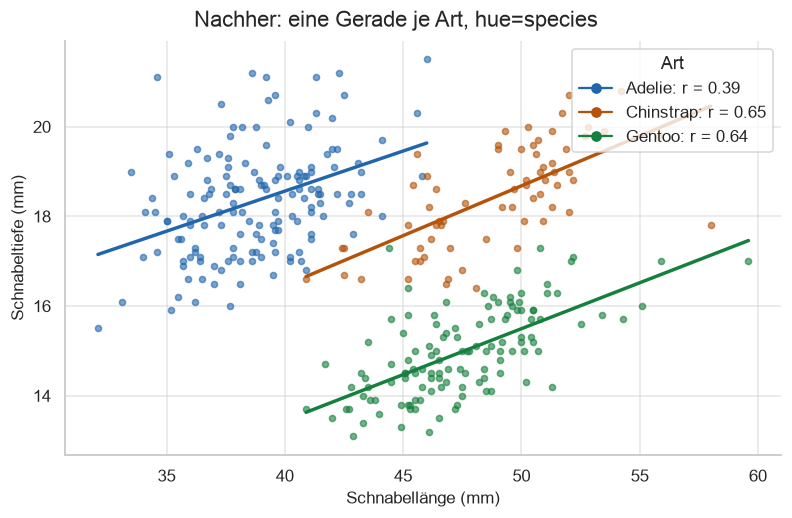

In [27]:
# Darstellen
fig, ax = plt.subplots(figsize=(7.5, 4.6))
sns.regplot(data=schnabel, x='bill_length_mm', y='bill_depth_mm', ci=None, color='#6B7280',
            scatter_kws={'s': 16, 'alpha': 0.5}, line_kws={'color': 'black'}, ax=ax)
ax.set(title=f"Vorher: eine Gerade für alle, r = {schnabel['bill_length_mm'].corr(schnabel['bill_depth_mm']):.2f}",
       xlabel='Schnabellänge (mm)', ylabel='Schnabeltiefe (mm)')
plt.show()

g = sns.lmplot(data=schnabel, x='bill_length_mm', y='bill_depth_mm', hue='species', palette=ARTEN,
               ci=None, height=4.6, aspect=1.6, scatter_kws={'s': 16, 'alpha': 0.6}, legend=False)
g.set_axis_labels('Schnabellänge (mm)', 'Schnabeltiefe (mm)')
g.ax.legend(handles=[plt.Line2D([], [], color=farbe, marker='o', label=f'{art}: r = {je_art.loc[art, "r"]:.2f}')
                     for art, farbe in ARTEN.items()], title='Art', loc='upper right')
g.figure.suptitle('Nachher: eine Gerade je Art, hue=species', y=1.02)
plt.show()

**Bedeutung.** Über alle Pinguine fällt die Tiefe mit der Länge (r = −0.24); innerhalb jeder Art steigt sie: Adelie 0.39, Chinstrap 0.65, Gentoo 0.64. Die Art ist die Drittvariable: Gentoo haben lange, flache Schnäbel (im Mittel 47.50 mm und 14.98 mm), Adelie kurze, tiefe (38.79 mm und 18.35 mm), und die gestaffelten Gruppen erzeugen im Aggregat einen fallenden Trend, der in keiner Art vorkommt. Berkeley zeigt dasselbe mit Quoten: In den sechs grössten Departementen sind es 44.5 Prozent gegen 30.3 Prozent im Aggregat (über alle Departemente nennt die Vorlesung 44 gegen 35 Prozent), aber in vier von sechs Departementen liegen die Frauen vorn; 93 Prozent ihrer Bewerbungen gingen an C bis F mit Quoten um ein Drittel oder darunter, bei den Männern waren es 49 Prozent. Der Mittelwert der Quoten (38.2 gegen 41.7) wäre die falsche Rechnung. Die Regel für den Bericht: Bevor ihr eine Richtung berichtet, färbt nach der Gruppe und rechnet je Gruppe.

> **Euer Datensatz.** Welche Gruppenvariable könnte bei euch das Vorzeichen drehen? Plottet mit `hue` und rechnet r je Gruppe, bevor ihr eine Richtung berichtet.

> **Take-Home Zusammenhang und Ursache**
>
> 1. **Drittvariable:** Eine gemeinsame Ursache Z erzeugt eine Korrelation ohne Wirkung. Nach Z aufteilen.
> 2. **Trends:** Zwei wachsende Reihen korrelieren fast immer. Die Veränderungen prüfen.
> 3. **Simpson:** Das Aggregat kann umkehren. Immer auch die Gruppen ansehen, Gesamtquoten als Summe durch Summe.
> 4. **Kausal** braucht Reihenfolge, geprüfte Drittvariablen und einen Nachweis.
>
> Plotten, messen, robust gegenprüfen, Ursache hinterfragen.

---

## 5. Viele Variablen auf einmal

*Vorlesung: keine eigene Folie; Heatmap und Pairplot ergänzen den Prüfpfad für viele Paare. Leitfrage: Wie findet man unter vielen Paaren die, die den Plot verdienen?*

Der Prüfpfad der Vorlesung gilt pro Paar. Ein Datensatz mit sechs metrischen Spalten hat 15 Paare: Heatmap und Pairplot sind die Landkarte, auf der man die Paare auswählt, die danach einzeln durch den Prüfpfad gehen.

### 5.1 Korrelationsmatrix und Heatmap

**Problem.** Der Titanic-Datensatz hat sechs numerische Spalten, also 15 Paare. Niemand zeichnet 15 Streudiagramme zuerst. Welche Paare lohnen den Plot, und was bedeutet eine Korrelation mit `survived` oder `pclass`?

**Theorie.** *Vorlesung: Folie «Der Prüfpfad für jeden Zusammenhang», Schritt 01 «Form lesen».*

Die Korrelationsmatrix rechnet das gewählte Mass für jedes Paar von Spalten; pandas nimmt dabei je Paar die Zeilen, die beide Werte haben, n kann also von Paar zu Paar verschieden sein. Die Heatmap färbt die Matrix: Farbe für Vorzeichen und Betrag, die Zahl im Feld. Sie ersetzt das Streudiagramm nicht: Jedes Feld presst eine Wolke in eine Zahl, die Form sieht man nur im Plot. Und nicht jede Zahlenspalte ist metrisch: `survived` ist binär, `pclass` ordinal (NB01). Für sie ist Pearson höchstens ein Richtungshinweis, das Rangmass der ehrlichere Wert.

**Code.** `.corr(numeric_only=True)` als Pearson und als Spearman, dazu n je Paar. Vorher ist die gedruckte Zahlenmatrix, in der man die grossen Beträge suchen muss; nachher dieselben Zahlen als Heatmap, links Pearson, rechts Spearman.

In [28]:
# Rechnen
numerisch = titanic.select_dtypes('number')
print(f'Numerische Spalten: {list(numerisch.columns)}')

vorhanden = numerisch.notna().astype(int)
n_je_paar = vorhanden.T @ vorhanden                       # Zeilen, die beide Werte haben
print(f"n je Paar: ohne Alter {n_je_paar.loc['fare', 'pclass']}, mit Alter {n_je_paar.loc['age', 'fare']}")

r_matrix = numerisch.corr(numeric_only=True)              # Pearson, paarweise vollständige Zeilen
rho_matrix = numerisch.corr(method='spearman')
print('\nPearson r:')
print(r_matrix.round(2).to_string())

Numerische Spalten: ['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']
n je Paar: ohne Alter 891, mit Alter 714

Pearson r:
          survived  pclass   age  sibsp  parch  fare
survived      1.00   -0.34 -0.08  -0.04   0.08  0.26
pclass       -0.34    1.00 -0.37   0.08   0.02 -0.55
age          -0.08   -0.37  1.00  -0.31  -0.19  0.10
sibsp        -0.04    0.08 -0.31   1.00   0.41  0.16
parch         0.08    0.02 -0.19   0.41   1.00  0.22
fare          0.26   -0.55  0.10   0.16   0.22  1.00


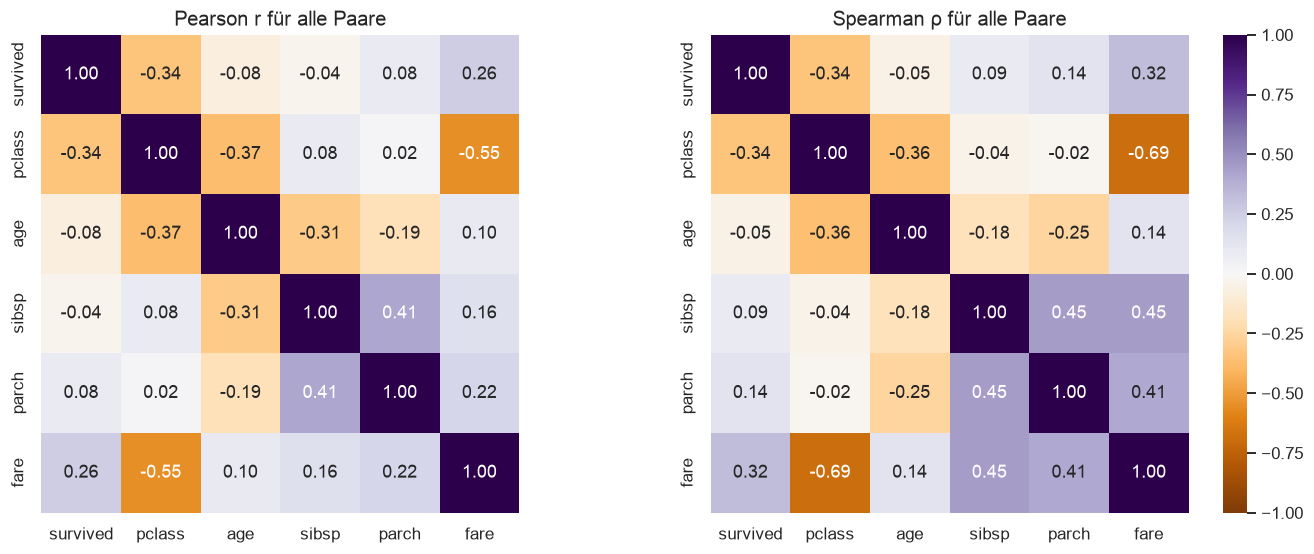

In [29]:
# Darstellen
fig, achsen = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, matrix, titel in [(achsen[0], r_matrix, 'Pearson r für alle Paare'),
                          (achsen[1], rho_matrix, 'Spearman ρ für alle Paare')]:
    sns.heatmap(matrix, annot=True, fmt='.2f', vmin=-1, vmax=1, center=0, cmap='PuOr', square=True,
                cbar=ax is achsen[1], ax=ax)
    ax.set(title=titel)
plt.tight_layout()
plt.show()

**Bedeutung.** Den grössten Betrag hat Preis und Klasse: r −0.55, als Rangmass −0.69, denn die Klasse ist ordinal und der Preis rechtsschief. Alter und Preis stehen mit 0.10 da, wie in 2.2, berechnet auf 714 statt 891 Zeilen; n je Paar gehört neben die Matrix. `sibsp` und `parch` hängen zusammen (0.41): Familien reisen zusammen. Die Zeile `survived` ist ein Hinweis auf Gruppenunterschiede, etwa beim Preis (0.26), kein Zusammenhang zweier Messgrössen; das Werkzeug dafür kommt mit den Gruppenvergleichen. Die Heatmap ist die Landkarte, die zwei oder drei Paare mit grossem Betrag gehen danach einzeln durch den Prüfpfad.

> **Euer Datensatz.** Zeichnet die Heatmap eurer metrischen Variablen. Welche zwei Paare haben den grössten Betrag, und welche Spalte darin ist gar nicht metrisch?

### 5.2 Pairplot lesen

**Problem.** Vier Pinguin-Masse ergeben sechs Paare. Im Pairplot ohne Farbe sieht man sechs Wolken; mit `hue='species'` werden es 18 Teilwolken. Wo steckt Simpson, und welche Paare verdienen ein eigenes Streudiagramm?

**Theorie.** *Vorlesung: Folie «Der Prüfpfad für jeden Zusammenhang», Schritt 01 «Form lesen».*

Der Pairplot ist das Gitter aller Streudiagramme: Die Diagonale zeigt die Verteilung jeder Variable (Histogramm oder KDE wie in NB02 und NB03), die übrigen Felder je ein Paar. `hue` färbt nach einer Gruppenvariable und macht Mischungen sichtbar, auf der Diagonale als mehrere Modi, in den Feldern als gestaffelte Teilwolken. Lesen in dieser Reihenfolge: zuerst die Diagonale, dann Richtung und Form der Felder, dann die Zahl je Gruppe.

**Code.** $r$ je Art für alle sechs Paare als Tabelle. Vorher der Pairplot ohne Gruppen, nachher mit `hue='species'`.

In [30]:
# Rechnen
masse = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
pinguine = penguins[masse + ['species']].dropna()

zeilen = []
for i in range(len(masse)):
    for j in range(i + 1, len(masse)):
        zeile = {'Paar': f'{masse[i]} und {masse[j]}', 'alle': pinguine[masse[i]].corr(pinguine[masse[j]])}
        for art, gruppe in pinguine.groupby('species'):
            zeile[art] = gruppe[masse[i]].corr(gruppe[masse[j]])
        zeilen.append(zeile)
pd.DataFrame(zeilen).set_index('Paar').round(2)

,alle,Adelie,Chinstrap,Gentoo
Paar,,,,
bill_length_mm und bill_depth_mm,-0.24,0.39,0.65,0.64
bill_length_mm und flipper_length_mm,0.66,0.33,0.47,0.66
bill_length_mm und body_mass_g,0.60,0.55,0.51,0.67
bill_depth_mm und flipper_length_mm,-0.58,0.31,0.58,0.71
bill_depth_mm und body_mass_g,-0.47,0.58,0.60,0.72
flipper_length_mm und body_mass_g,0.87,0.47,0.64,0.70


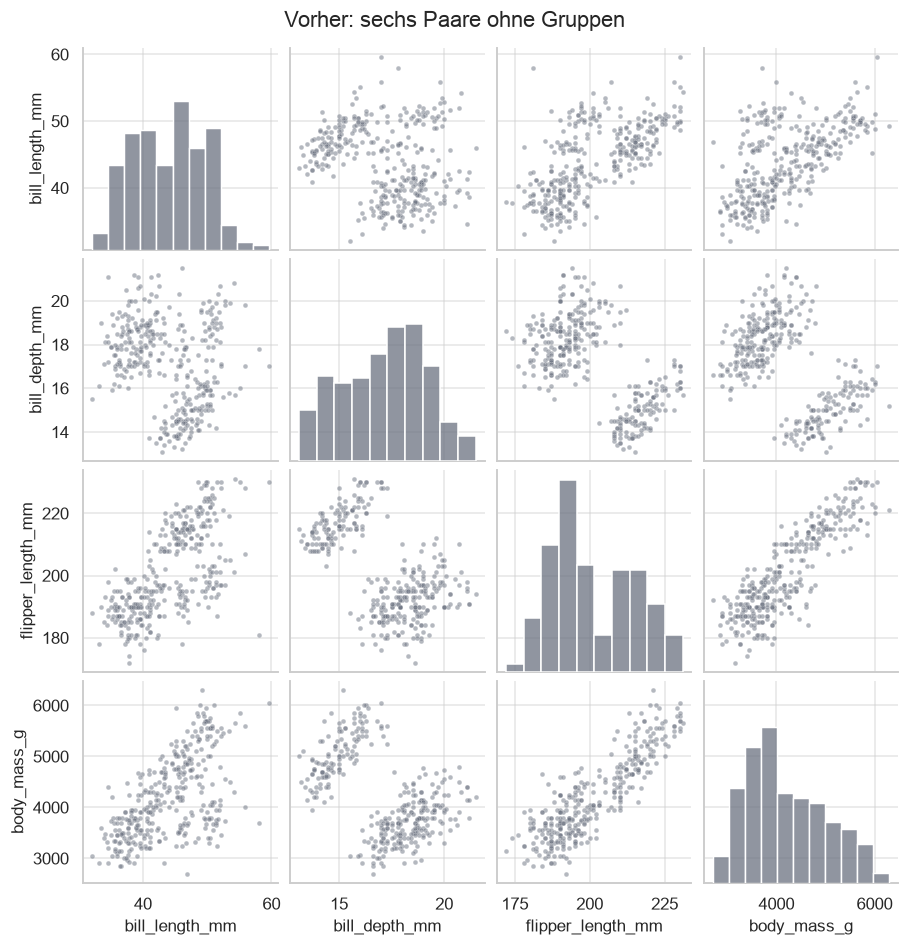

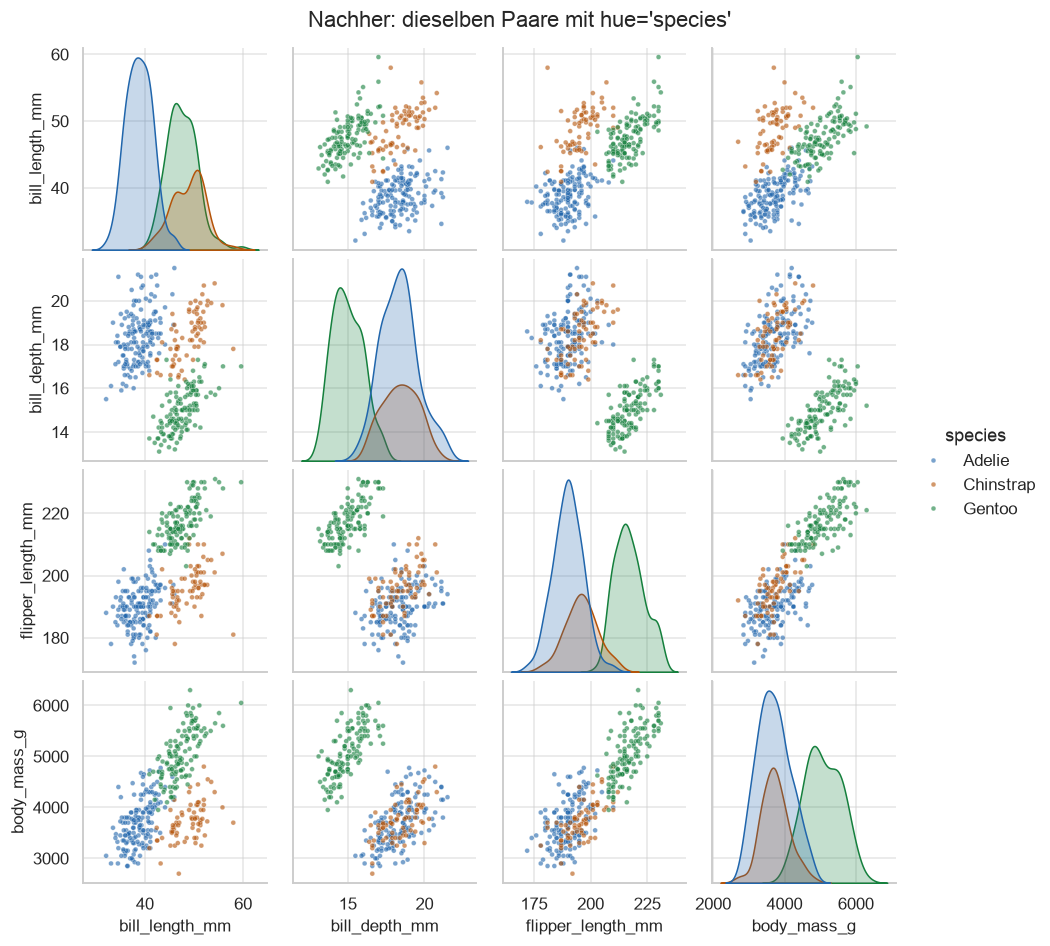

In [31]:
# Darstellen
g = sns.pairplot(pinguine[masse], height=2.1, plot_kws={'color': '#6B7280', 's': 10, 'alpha': 0.5},
                 diag_kws={'color': '#6B7280'})
g.figure.suptitle('Vorher: sechs Paare ohne Gruppen', y=1.02)
plt.show()

g = sns.pairplot(pinguine, hue='species', palette=ARTEN, height=2.1, plot_kws={'s': 10, 'alpha': 0.6})
g.figure.suptitle("Nachher: dieselben Paare mit hue='species'", y=1.02)
plt.show()

**Bedeutung.** Ohne Farbe zeigt die Diagonale die bimodale Flossenlänge aus NB02 und NB03 und die Felder sechs Wolken, drei davon fallend. Mit `hue` erklärt sich beides: Die Flossen sind eine Mischung der Arten, und Simpson sitzt in allen drei Paaren mit der Schnabeltiefe: gegen die Schnabellänge (alle −0.24, je Art 0.39 bis 0.65), gegen die Flossenlänge (alle −0.58, je Art 0.31 bis 0.71) und gegen das Gewicht (alle −0.47, je Art 0.58 bis 0.72). Flossenlänge gegen Gewicht bleibt in jeder Art positiv (0.47 bis 0.70), dieses Paar hält dem Aufteilen stand. Die drei Paare mit der Schnabeltiefe verdienen das eigene Streudiagramm, mit `hue` und einer Zahl je Art. Der Pairplot ist die Karte für den EDA-Report; die Entscheidungen fallen in den einzelnen Bildern.

> **Euer Datensatz.** Welche zwei Paare aus eurem Pairplot verdienen ein eigenes Streudiagramm, und welche Gruppenvariable färbt ihr dabei?

---

## 6. Zusammenfassung und Übertragung

Die vier Lernziele der Vorlesung, jeweils mit der Stelle, an der sie im Notebook laufen:

| # | Lernziel | Abschnitt |
|---|---|---|
| 01 | **Form lesen**: Richtung, Form und Stärke eines Zusammenhangs im Streudiagramm erkennen | 1, 5 |
| 02 | **Linear messen**: Kovarianz und Pearson r berechnen und ihre Grenzen benennen | 2 |
| 03 | **Robust messen**: Spearman und Kendall für monotone Muster und Ausreisser wählen | 3 |
| 04 | **Fehlschlüsse erkennen**: Drittvariablen, Scheinkorrelation und Simpson-Paradox erkennen | 4 |

Die wichtigsten drei Sätze des Notebooks:

1. **Erst plotten, dann rechnen.** Die Zahl verrät die Form nicht: Eine Kurve hat r = 0.89, ein perfektes U hat r = 0; ein r ohne Streudiagramm gehört nicht in einen Bericht.
2. **Die Form wählt das Mass.** Pearson für gerade Wolken ohne Ausreisser, Spearman oder Kendall für monotone Muster, Ordinalskalen und Ausreisser; ein U sieht keines.
3. **Vor jeder Ursache: Drittvariable, Trend, Gruppen.** Nach Z aufteilen, Veränderungen statt Niveaus, mit `hue` färben, bevor ihr eine Richtung berichtet.

### Transfer in der Übung

Die drei Schritte übertragen die Unterabschnitte 3.1, 4.3 und 5.2 auf euren eigenen Datensatz.

**1. Die Karte.** Pairplot oder Heatmap eurer metrischen Variablen. Wählt das eine Paar, das eure Forschungsfrage trägt, und nennt n (Zeilen mit beiden Werten).

**2. Die Zahl.** Streudiagramm des Paars, Form benennen (linear, monoton, weder noch), dann Pearson und Spearman mit `method=`. Entscheidet, welches Mass in den Bericht kommt, und begründet es mit Form, Ausreissern oder Skala. Ist eine der beiden Variablen ordinal, gilt Schritt 5 im nächsten Abschnitt: Kendall statt Pearson, Boxplot je Stufe statt Streudiagramm.

**3. Die Gruppen.** Färbt das Streudiagramm mit `hue` nach der plausibelsten Gruppenvariable und rechnet das Mass je Gruppe. Hält die Richtung innerhalb der Gruppen?

**Erwartetes Ergebnis** im Entscheidungs-Log der Gruppe: eine Entscheidung mit Begründung und ein Berichtssatz nach dem Muster «Zwischen x und y: r = …, ρ = …, n = …, Form …; innerhalb der Gruppen von z …; wir berichten …, weil …».

**Ersatzdatensatz** für Gruppen ohne eigene Daten: `tips` aus seaborn, Paar `total_bill` und `tip`, Gruppenvariable `time` oder `size`.

### Was ihr mit eurem eigenen Datensatz macht

Die Fragen **Euer Datensatz** in den Abschnitten 1 bis 5 führen durch diese Schritte.

**1. Das Paar festlegen.** Zwei metrische Variablen, x die erklärende. Nennt n als Zahl der Zeilen mit beiden Werten und die Zahl der weggefallenen Zeilen.

**2. Erst plotten.** Streudiagramm mit Randverteilungen. Benennt Richtung, Form (linear, monoton, weder noch) und Stärke als Wörter, bevor eine Zahl fällt.

**3. Pearson nur für gerade Wolken.** Rechnet r und übersetzt es mit der Faustregel; sie gilt nur ohne Krümmung und ohne Ausreisser.

**4. Rangmass als Gegenprobe.** Rechnet ρ mit `method='spearman'`, bei Ordinalskalen oder vielen Ties auch τ. Weichen r und ρ deutlich ab, ist die Form oder ein einzelner Punkt der Grund.

**5. Wenn eure Variablen vor allem ordinal sind.** Viele Projektdatensätze haben Stufen (Noten, Likert-Skalen, Kategorien mit Reihenfolge) und nur eine oder zwei metrische Spalten. Dann gilt: Prüft zuerst, ob die Variable wirklich geordnet ist; Region oder Gerätetyp haben keine Reihenfolge, und für sie gibt es keine Korrelation, sondern einen Gruppenvergleich (später im Semester). Geordnete Stufen kodiert ihr als ganze Zahlen in der richtigen Reihenfolge. Für ordinal mit metrisch rechnet ihr Kendall τ oder Spearman ρ wie in 3.2 und zeichnet statt des Streudiagramms einen Boxplot oder Strip-Plot der metrischen Variable je Stufe (NB03). Für ordinal mit ordinal passt Kendall τ, weil es wenige Stufen und viele Ties gibt; das Bild dazu ist eine Kreuztabelle oder ein Streudiagramm mit Jitter, sonst sehen alle Punkte gleich aus. Die Heatmap rechnet ihr mit `method='kendall'` oder `'spearman'`, nie mit Pearson über Likert-Spalten. Pearson und die Faustregel aus Schritt 3 bleiben den metrischen Paaren vorbehalten.

**6. Drittvariablen und Gruppen.** Welche Grösse könnte beide Variablen treiben? Teilt nach ihr auf oder färbt mit `hue`; ordinale Variablen sind dafür gute Gruppenvariablen. Bei Zeitreihen die Veränderungen korrelieren. Berichtet eine Richtung erst, wenn sie innerhalb der Gruppen hält.

**7. Einen vollständigen Satz schreiben.** Mass mit Namen, Wert, n, Form, Skalenniveau der beiden Variablen, Umgang mit Gruppen, Verweis auf die Grafik. Eine Korrelation ohne Grafik ist kein Befund.

**Was VL04 bewusst noch nicht beantwortet.** Ob ein r von 0.3 bei eurem n mehr als Zufall ist, klären Konfidenzintervalle und Tests (VL06 und VL07); Korrelation ist hier ein exploratives Werkzeug. Wie man eine Drittvariable rechnerisch herausnimmt, kommt mit der Regression (VL10 und VL11), dort kehrt Simpson als Vorzeichenwechsel eines Koeffizienten zurück. Zusammenhänge mit einer binären Zielvariable wie `survived` brauchen die Gruppenvergleiche. Und keine Zahl entscheidet, ob ein Zusammenhang eine Ursache ist: Das bleibt Design, Reihenfolge und fachliche Prüfung.

---

**Weiter in VL05:** Wahrscheinlichkeit, also Erwartungswert und Varianz einer Zufallsvariable, die Verteilungen Bernoulli, Binomial und Poisson, das Gesetz der grossen Zahlen und der Satz von Bayes.